# The Geometry of Inheritance


## Settings

Change `sample_index` to work with another genotype. I keep `training_steps = 850` for these comparisons and set `render_videos = False` when I only need the figures.

The data are included below. To run the notebook locally, install the packages in `requirements.txt` and open it in Jupyter. FFmpeg is needed for the videos. Outputs are saved in `genome_art_outputs/`.

In [ ]:
#set the sample, training settings, and output folder

import os


os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

import base64
import hashlib
import io
import json
import pathlib
import shutil
import struct
import subprocess
from dataclasses import dataclass

import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image as RasterImage
from IPython.display import display, Video, Image, FileLink

try:
    from threadpoolctl import threadpool_limits

    threadpool_limits(limits=2)
except ImportError:
    pass

seed = 77
training_steps = 850
sample_index = 0
chosen_indices = [0, 250, 500, 1000, 1200]
hero_indices = [0, 500, 1000]
phase = 0.12
random_seed = 2026
render_videos = True
video_size = 800
video_fps = 20

out = pathlib.Path("genome_art_outputs")
for folder in ["images", "animations", "meshes", "data"]:
    (out / folder).mkdir(parents=True, exist_ok=True)

plt.rcdefaults()
plt.rcParams.update(
    {
        "figure.dpi": 105,
        "savefig.dpi": 200,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "normal",
        "axes.titlesize": 11,
    }
)
saved_plots = []
experiment_results = {}


def write_bytes(path, data):
    path = pathlib.Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_bytes(data)
    temporary.replace(path)


def save_npz(path, **arrays):
    buffer = io.BytesIO()
    np.savez_compressed(buffer, **arrays)
    write_bytes(path, buffer.getvalue())


def save_plot(fig, filename):
    if not getattr(fig, "_keep_layout", False):
        fig.tight_layout(pad=1.0)
    path = out / "images" / filename
    fig.savefig(path, facecolor=fig.get_facecolor(), bbox_inches="tight")
    saved_plots.append(filename)
    display(Image(filename=str(path), width=1000))
    plt.close(fig)


def hsv_to_rgb(hsv):
    hsv = np.asarray(hsv, dtype=float)
    hue, saturation, value = np.moveaxis(hsv, -1, 0)
    sector = np.floor(6 * hue).astype(int)
    fraction = 6 * hue - sector
    low = value * (1 - saturation)
    falling = value * (1 - saturation * fraction)
    rising = value * (1 - saturation * (1 - fraction))
    candidates = np.stack(
        [
            np.stack([value, rising, low], -1),
            np.stack([falling, value, low], -1),
            np.stack([low, value, rising], -1),
            np.stack([low, falling, value], -1),
            np.stack([rising, low, value], -1),
            np.stack([value, low, falling], -1),
        ]
    )
    return np.take_along_axis(candidates, (sector % 6)[None, ..., None], axis=0)[0]


def radial_xyz(radius, theta, phi):
    return np.stack(
        [
            radius * np.cos(phi) * np.cos(theta),
            radius * np.cos(phi) * np.sin(theta),
            radius * np.sin(phi),
        ],
        axis=-1,
    )


def face_shading(mesh):
    normals = -np.cross(mesh[:, 1] - mesh[:, 0], mesh[:, 2] - mesh[:, 0])
    normals /= np.linalg.norm(normals, axis=1, keepdims=True) + 1e-12
    light = np.array([1.0, -1.0, 2.0]) / np.sqrt(6)
    return 0.62 + 0.38 * np.maximum(normals @ light, 0)


def plot_surface(ax, xyz, colors=None, wire=False, limits=2.1, azimuth=38):
    if wire:
        ax.plot_wireframe(
            *np.moveaxis(xyz, -1, 0),
            color="0.35",
            linewidth=0.4,
            rstride=max(1, xyz.shape[0] // 16),
            cstride=max(1, xyz.shape[1] // 24)
        )
    else:
        faces = triangles(*xyz.shape[:2])
        mesh = xyz.reshape(-1, 3)[faces]
        pigment = (
            np.array([0.37, 0.55, 0.68])
            if colors is None
            else colors.reshape(-1, 3)[faces].mean(axis=1)
        )
        artist = Poly3DCollection(
            mesh,
            edgecolors="none",
            linewidths=0,
            facecolors=face_shading(mesh)[:, None] * pigment,
        )
        ax.add_collection3d(artist)
    ax.set(xlim=(-limits, limits), ylim=(-limits, limits), zlim=(-limits, limits))
    ax.set_box_aspect((1, 1, 1), zoom=1.22)
    ax.view_init(24, azimuth)
    ax.set_axis_off()


print("Outputs:", out.resolve())


## Genotype data

I use 768 chromosome-22 sites from 2,504 people in the 1000 Genomes Phase 3 dataset. The selection takes every 14th biallelic SNP marked PASS or “.”, then keeps sites with minor-allele frequency between 0.03 and 0.50 and no more than 2% missing calls.

The compressed data include the sample IDs and variant positions. A value of −1 marks a missing call and becomes NaN after loading. The checksum checks this saved selection. The original VCF checksum wasn't recorded.

In [ ]:
#load the 768 selected sites and check the dosage values

encoded_data = '...'
data_bytes = base64.b64decode(encoded_data)
assert hashlib.sha256(data_bytes).hexdigest() == 'e2af9b05465f93d60ce1d3b12ebfcbadba9faec8a2fb0e67a05ea6804af11727'
with np.load(io.BytesIO(data_bytes), allow_pickle=False) as data:
    Graw = data['dosages'].astype(np.float32)
    Graw[Graw < 0] = np.nan
    sample_ids = data['sample_ids'].copy()
    variants = json.loads(str(data['variants']))
    data_audit = json.loads(str(data['audit']))
positions = np.array([site['pos'] for site in variants])
assert Graw.shape == (2504, 768)
assert len(np.unique(sample_ids)) == 2504
assert np.isin(Graw[np.isfinite(Graw)], [0, 1, 2]).all()
assert np.isfinite(Graw).any(axis=0).all()
write_bytes(out / 'data' / 'genotypes.npz', data_bytes)
print(Graw.shape, 'samples × sites')
print('Chr22 positions:', positions.min(), 'to', positions.max())
print('Missing calls:', np.isnan(Graw).sum())


(2504, 768) samples × sites
Chr22 positions: 16058883 to 19634204
Missing calls: 0


## Autoencoder and Adam

I use a $768\to72\to12\to72\to768$ network to compress each genotype into twelve values. During training, I add Gaussian noise to the input and reconstruct the original batch $X$.

$$H=\tanh(X_nW_1+b_1),\qquad L=HW_z+b_z$$
$$H_d=\tanh(LV_1+c_1),\qquad \hat X=H_dV_2+c_2$$

The loss combines reconstruction error with a small penalty on the latent values.

$$\mathcal L=\operatorname{mean}((\hat X-X)^2)+0.0008\operatorname{mean}(L^2)$$

For a batch of $B$ records and $D=768$ sites, the output gradient is $2(\hat X-X)/(BD)$. I work backward through each layer using $\tanh'(u)=1-\tanh^2(u)$. At the bottleneck, I add $2\lambda L/(B\cdot12)$ for the latent penalty.

Adam tracks moving averages of the gradients and their squares. I correct their initial bias by dividing by $1-\beta_1^t$ and $1-\beta_2^t$, then update each parameter using the corrected averages.

In [ ]:
#define the encoder, decoder, loss gradients, and adam updates

@dataclass
class AdamState:
    m: dict
    v: dict
    t: int = 0


class NumpyLatentAutoencoder:
    def __init__(self, input_dim, hidden_dim=72, latent_dim=12, seed=77):
        self.rng = np.random.default_rng(seed)
        s1 = np.sqrt(2.0 / (input_dim + hidden_dim))
        s2 = np.sqrt(2.0 / (hidden_dim + latent_dim))
        s3 = np.sqrt(2.0 / (latent_dim + hidden_dim))
        self.P = {
            "W1": self.rng.normal(0, s1, (input_dim, hidden_dim)).astype(np.float32),
            "b1": np.zeros(hidden_dim, dtype=np.float32),
            "Wz": self.rng.normal(0, s2, (hidden_dim, latent_dim)).astype(np.float32),
            "bz": np.zeros(latent_dim, dtype=np.float32),
            "V1": self.rng.normal(0, s3, (latent_dim, hidden_dim)).astype(np.float32),
            "c1": np.zeros(hidden_dim, dtype=np.float32),
            "V2": self.rng.normal(0, s1, (hidden_dim, input_dim)).astype(np.float32),
            "c2": np.zeros(input_dim, dtype=np.float32),
        }
        self.opt = AdamState(
            m={k: np.zeros_like(v) for k, v in self.P.items()},
            v={k: np.zeros_like(v) for k, v in self.P.items()},
        )

    def encode(self, X):
        h = np.tanh(X @ self.P["W1"] + self.P["b1"])
        z = h @ self.P["Wz"] + self.P["bz"]
        return z

    def forward(self, X, noise_sigma=0.0):
        if noise_sigma > 0:
            Xn = X + self.rng.normal(0, noise_sigma, X.shape).astype(np.float32)
        else:
            Xn = X
        h = np.tanh(Xn @ self.P["W1"] + self.P["b1"])
        z = h @ self.P["Wz"] + self.P["bz"]
        g = np.tanh(z @ self.P["V1"] + self.P["c1"])
        y = g @ self.P["V2"] + self.P["c2"]
        cache = (Xn, h, z, g, y)
        return y, cache

    def loss_and_gradients(self, Xb, noise_sigma=0.0, latent_l2=8e-4):
        B, D = Xb.shape
        y, (Xn, h, z, g, _) = self.forward(Xb, noise_sigma=noise_sigma)
        diff = y - Xb
        loss_recon = float(np.mean(diff * diff))
        loss_latent = float(latent_l2 * np.mean(z * z))
        dY = (2.0 / (B * D)) * diff

        grads = {}
        grads["V2"] = g.T @ dY
        grads["c2"] = dY.sum(axis=0)
        dG = dY @ self.P["V2"].T
        dA2 = dG * (1.0 - g * g)
        grads["V1"] = z.T @ dA2
        grads["c1"] = dA2.sum(axis=0)
        dZ = dA2 @ self.P["V1"].T
        dZ += (2.0 * latent_l2 / (B * z.shape[1])) * z
        grads["Wz"] = h.T @ dZ
        grads["bz"] = dZ.sum(axis=0)
        dH = dZ @ self.P["Wz"].T
        dA1 = dH * (1.0 - h * h)
        grads["W1"] = Xn.T @ dA1
        grads["b1"] = dA1.sum(axis=0)

        return loss_recon + loss_latent, loss_recon, loss_latent, grads

    def step(self, Xb, lr=2e-3, noise_sigma=0.08, latent_l2=8e-4, beta1=0.9, beta2=0.999):
        total, loss_recon, loss_latent, grads = self.loss_and_gradients(
            Xb, noise_sigma, latent_l2
        )
        self.opt.t += 1
        t = self.opt.t
        for k in self.P:
            gk = grads[k].astype(np.float32)
            self.opt.m[k] = beta1 * self.opt.m[k] + (1 - beta1) * gk
            self.opt.v[k] = beta2 * self.opt.v[k] + (1 - beta2) * (gk * gk)
            mh = self.opt.m[k] / (1 - beta1**t)
            vh = self.opt.v[k] / (1 - beta2**t)
            self.P[k] -= lr * mh / (np.sqrt(vh) + 1e-8)

        return loss_recon + loss_latent, loss_recon, loss_latent


## Gradient check

Before fitting the full model, I compare the backpropagation gradients with central finite differences on a small network. I turn noise off for this check so both calculations use the same input. The maximum error is printed below.

In [ ]:
# heck the gradients against finite differences on a small network

check_model = NumpyLatentAutoencoder(7, hidden_dim=5, latent_dim=3, seed=11)
check_model.P = {name: value.astype(np.float64) for name, value in check_model.P.items()}
check_batch = np.random.default_rng(12).normal(size=(4, 7))
_, _, _, analytic = check_model.loss_and_gradients(check_batch)
epsilon = 1e-5
gradient_errors = {}
for name, parameter in check_model.P.items():
    errors = []
    for flat_index in np.linspace(0, parameter.size - 1, min(8, parameter.size), dtype=int):
        index = np.unravel_index(flat_index, parameter.shape)
        original = parameter[index]
        parameter[index] = original + epsilon
        high = check_model.loss_and_gradients(check_batch)[0]
        parameter[index] = original - epsilon
        low = check_model.loss_and_gradients(check_batch)[0]
        parameter[index] = original
        numerical = (high - low) / (2 * epsilon)
        errors.append(abs(numerical - analytic[name][index]))
    gradient_errors[name] = float(max(errors))
assert max(gradient_errors.values()) < 1e-8, gradient_errors
experiment_results["gradient_check_max_absolute_error"] = gradient_errors
print("Backpropagation check:", max(gradient_errors.values()))


Backpropagation check: 2.3487795042242965e-11


## Geometry and color equations

The surface starts at radius 1.25. I add the broad waves, pleats, and fine ripples with different weights.

$$r=1.25+0.28\sum_i B_i+0.11\sum_i P_i+0.035F$$

I then apply an angular twist, a transverse pinch, and a vertical deformation. Here $\varphi$ is latitude. The polar angle in the OCW notes is $\pi/2-\varphi$.

I divide each latent vector by its RMS magnitude and apply softsign before using it for the amplitudes. The first four bounded values control broad waves and the next four control pleats. Within the last group, `c[0:3]` enter the phase and deformation equations directly. `c[3]` has no separate deformation term. Its source coordinate still affects the other coefficients through RMS normalization.

For the palette, I apply an orthonormal DCT-II to the standardized latent vector.

$$C_{kj}=\alpha_k\cos\left[\frac{\pi(j+1/2)k}{12}\right],\qquad q=\tanh(Cz)$$

Here $\alpha_0=1/\sqrt{12}$ and $\alpha_k=\sqrt{2/12}$ for the other rows. I use $q$ to calculate three HSV anchors and convert them to RGB.

To distribute those colors, I weight twelve polynomial fields on the unit sphere with three cyclic shifts of $q$. These are unnormalized real harmonic fields. The expression $3s^2-1$ on the sphere is equivalent to the harmonic polynomial $2s^2-x^2-y^2$.

$$w_i=\frac{\exp(\beta f_i)}{\sum_j\exp(\beta f_j)},\qquad \beta=4+q_{11},\qquad \mathrm{RGB}=\sum_iw_ic_i$$

I subtract the largest logit before exponentiating to avoid overflow. The weights stay positive and sum to one, so the blended RGB values stay in range. All twelve latent values enter the color calculation.

In [ ]:
#define the radial terms, deformations, palette, and color fields

k = np.arange(12)[:, None]
j = np.arange(12)[None, :]
color_basis = np.sqrt(2 / 12) * np.cos(np.pi * (j + 0.5) * k / 12)
color_basis[0] /= np.sqrt(2)


def softsign(x):
    return x / (1 + np.abs(x))


def coefficients(z):
    z = np.asarray(z, dtype=float)
    normalized = z / (np.linalg.norm(z) / np.sqrt(len(z)) + 1e-09)
    return np.split(softsign(normalized), 3)


def frequencies(z):
    return (2 + int(abs(z[0]) * 3), 3 + int(abs(z[1]) * 4), 5 + int(abs(z[2]) * 5))


def surface_terms(z, theta, phi, time=0.12, raw_amplitudes=False):
    a, b, c = coefficients(z)
    if raw_amplitudes:
        a, b = np.asarray(z[:4]), np.asarray(z[4:8])
    f1, f2, f3 = frequencies(z)
    tau = 2 * np.pi * time
    broad = np.stack(
        [
            a[0] * np.sin(f1 * theta + 1.7 * np.cos(phi) + tau),
            a[1] * np.cos(f2 * phi - 0.5 * theta + 0.7 * tau),
            a[2] * np.sin(f3 * (theta + phi) + c[0]),
            a[3] * np.cos((f1 + f2) * theta * 0.31 - 2 * phi + c[1]),
        ]
    )
    pleats = np.stack(
        [
            b[0] * np.sin(2 * theta + 5 * phi + tau),
            b[1] * np.sin(7 * theta - phi + 0.3 * tau),
            b[2] * np.cos(3 * theta + 4 * phi + c[2]),
            b[3] * np.sin(11 * theta * np.cos(phi) + c[0]),
        ]
    )
    fine = np.sin((abs(z[9]) + 1.5) * 13 * theta + (abs(z[10]) + 1) * 4 * phi + tau)
    twist = 0.45 * c[0] * np.sin(2 * phi + tau) + 0.22 * c[1] * np.sin(3 * theta)
    pinch = 1 + 0.16 * c[2] * np.cos(2 * phi) + 0.06 * c[0] * np.sin(6 * theta + tau)
    return (broad, pleats, fine, twist, pinch)


def grid(nt=120, np_=62):
    theta = np.linspace(0, 2 * np.pi, nt, endpoint=False)
    phi = np.linspace(-0.96 * np.pi / 2, 0.96 * np.pi / 2, np_)
    return np.meshgrid(theta, phi)


def surface(
    z,
    theta,
    phi,
    stage=9,
    time=0.12,
    pleat_weight=0.11,
    fine_weight=0.035,
    broad_terms=None,
    raw_amplitudes=False,
):
    broad, pleats, fine, twist, pinch = surface_terms(z, theta, phi, time, raw_amplitudes)
    a, b, c = coefficients(z)
    if broad_terms is None:
        broad_sum = broad[: min(stage, 4)].sum(axis=0) if stage else np.zeros_like(theta)
    else:
        broad_sum = broad[list(broad_terms)].sum(axis=0)
    radius = 1.25 + 0.28 * broad_sum
    if stage >= 5:
        radius = radius + pleat_weight * pleats.sum(axis=0)
    if stage >= 6:
        radius = radius + fine_weight * fine
    angle = theta + (twist if stage >= 7 else 0)
    xy_scale = pinch if stage >= 8 else 1
    x = radius * xy_scale * np.cos(phi) * np.cos(angle)
    y = radius * xy_scale * np.cos(phi) * np.sin(angle)
    if stage >= 9:
        zcoord = radius * (0.86 + 0.18 * c[1]) * np.sin(phi)
        zcoord += 0.18 * c[2] * np.sin(3 * theta + 2 * np.pi * time) * np.cos(phi)
    else:
        zcoord = radius * np.sin(phi)
    return np.stack([x, y, zcoord], axis=-1)


def triangles(nrows, ncols):
    faces = []
    for row in range(nrows - 1):
        for col in range(ncols):
            a = row * ncols + col
            b = row * ncols + (col + 1) % ncols
            c = (row + 1) * ncols + col
            d = (row + 1) * ncols + (col + 1) % ncols
            faces.extend([(a, c, d), (a, d, b)])
    return np.array(faces, dtype=np.int32)


def palette_parameters(vector):
    q = np.tanh(color_basis @ np.asarray(vector, dtype=float))
    center = (0.5 + 0.28 * q[0] + 0.28 * q[1] + 0.18 * q[2]) % 1
    spread = 0.26 + 0.1 * q[3]
    hues = (center + np.array([0, spread, -spread * (0.85 + 0.15 * q[4])])) % 1
    saturation = 0.65 + 0.17 * q[5:8]
    value = 0.83 + 0.12 * q[8:11]
    anchors = hsv_to_rgb(np.stack([hues, saturation, value], axis=-1))
    return (q, anchors)


def color_parts(vector, theta, phi):
    q, anchors = palette_parameters(vector)
    x = np.cos(phi) * np.cos(theta)
    y = np.cos(phi) * np.sin(theta)
    zz = np.sin(phi)
    harmonics = np.stack(
        [
            x,
            y,
            zz,
            x * y,
            y * zz,
            zz * x,
            x * x - y * y,
            3 * zz * zz - 1,
            x * (x * x - 3 * y * y),
            y * (3 * x * x - y * y),
            zz * (x * x - y * y),
            x * y * zz,
        ],
        axis=-1,
    )
    weights = np.stack([np.roll(q, 4 * i) for i in range(3)])
    fields = harmonics @ weights.T / np.sqrt(12)
    logits = (4 + q[11]) * fields
    # subtracting one constant leaves the softmax weights unchanged
    logits -= logits.max(axis=-1, keepdims=True)
    fractions = np.exp(logits)
    fractions /= fractions.sum(axis=-1, keepdims=True)
    rgb = fractions @ anchors
    return (q, anchors, fields, fractions, rgb)


def surface_colors(z, theta, phi):
    return color_parts(z, theta, phi)[-1]


## Preprocessing and training

I fill missing entries with the observed mean at that site, standardize each column, and clip values to ±3. Training uses batches of 192, a learning rate of 0.0022, Gaussian noise with σ = 0.08, and seed 77.

After fitting, I standardize each of the twelve bottleneck coordinates across samples. The RMS normalization used for geometry happens later, separately for each vector.

I fit on all 2,504 records. The reconstruction errors below describe this fitting set. I haven't used a held-out set for this comparison.

In [ ]:
#fit the model and standardize its twelve latent coordinates

G = Graw.astype(np.float32)
means = np.nanmean(G, axis=0)
G = np.where(np.isnan(G), means, G).astype(np.float32)
g_mean = G.mean(axis=0, keepdims=True)
g_std = G.std(axis=0, keepdims=True) + 1e-5
X = np.clip((G - g_mean) / g_std, -3, 3).astype(np.float32)

model = NumpyLatentAutoencoder(X.shape[1], hidden_dim=72, latent_dim=12, seed=seed)
losses = []
checkpoint_steps = [0, 50, 200, training_steps]
checkpoint_vectors = {0: model.encode(X[[sample_index]])[0].copy()}
for step in range(1, training_steps + 1):
    batch = model.rng.integers(0, len(X), size=192)
    total, reconstruction, penalty = model.step(X[batch], lr=0.0022, noise_sigma=0.08)
    losses.append((total, reconstruction, penalty))
    if step in checkpoint_steps:
        checkpoint_vectors[step] = model.encode(X[[sample_index]])[0].copy()
    if step % 100 == 0 or step == training_steps:
        print(step, round(reconstruction, 5))

losses = np.array(losses)
Zraw = model.encode(X).astype(np.float32)
z_mean = Zraw.mean(axis=0, keepdims=True)
z_std = Zraw.std(axis=0, keepdims=True) + 1e-6
Z = (Zraw - z_mean) / z_std
reconstructed = model.forward(X[[sample_index]])[0][0]
z = Z[sample_index].copy()
a, b, c = coefficients(z)
f1, f2, f3 = frequencies(z)
T, P = grid()
final_xyz = surface(z, T, P, time=phase)
assert np.isfinite(final_xyz).all()


check_theta, check_phi = grid(60, 32)
size_checks = [
    np.max(np.abs(surface(z, check_theta, check_phi, stage=s, time=phase))) for s in range(10)
]
size_checks += [
    np.max(np.abs(surface(Z[i], check_theta, check_phi, time=phase))) for i in chosen_indices
]
plot_limit = float(max(size_checks) * 1.05)
save_npz(
    out / "model.npz",
    **model.P,
    g_mean=g_mean,
    g_std=g_std,
    z_mean=z_mean,
    z_std=z_std,
    Z=Z,
    X=X,
    sample_ids=np.array(sample_ids),
    losses=losses,
    checkpoint_steps=np.array(checkpoint_steps),
    checkpoint_vectors=np.stack([checkpoint_vectors[s] for s in checkpoint_steps])
)
print("Sample:", sample_ids[sample_index], "| frequencies:", f1, f2, f3)


100 0.64761
200 0.65263
300 0.63382
400 0.64018
500 0.60873
600 0.60478
700 0.62759
800 0.60351
850 0.59657
Sample: HG00096 | frequencies: 4 8 7


## Encoding new inputs

Every edited or random genotype goes through the same preprocessing statistics and fitted weights. I also check the DCT matrix, color agreement at the seam and poles, and the range of the blended RGB values.

In [ ]:
#encode new dosages with the fitted model and check the color calculations

def encode_counts(counts):
    counts = np.asarray(counts, dtype=np.float32)
    single = counts.ndim == 1
    counts = np.atleast_2d(counts)
    if counts.shape[1] != 768:
        raise ValueError("Expected 768 dosages in the selected-site order.")
    observed = counts[np.isfinite(counts)]
    if np.isinf(counts).any() or not np.isin(observed, [0, 1, 2]).all():
        raise ValueError("Dosages must be 0, 1, 2, or NaN for missing calls.")
    filled = np.where(np.isnan(counts), g_mean, counts)
    transformed = np.clip((filled - g_mean) / g_std, -3, 3).astype(np.float32)
    encoded = (model.encode(transformed) - z_mean) / z_std
    return encoded[0] if single else encoded


assert np.allclose(encode_counts(Graw[sample_index]), z, atol=2e-5)
assert np.isfinite(encode_counts(np.full(768, np.nan))).all()
assert np.allclose(color_basis @ color_basis.T, np.eye(12), atol=1e-12)
check_phi = np.linspace(-np.pi / 2, np.pi / 2, 93)
assert np.allclose(
    surface_colors(z, np.zeros_like(check_phi), check_phi),
    surface_colors(z, np.full_like(check_phi, 2 * np.pi), check_phi),
)
check_theta = np.linspace(0, 2 * np.pi, 101)
for pole in [-np.pi / 2, np.pi / 2]:
    pole_colors = surface_colors(z, check_theta, np.full_like(check_theta, pole))
    assert np.allclose(pole_colors, pole_colors[0])
_, _, _, fraction_check, rgb_check = color_parts(z, T, P)
assert np.allclose(fraction_check.sum(axis=-1), 1)
assert np.all((rgb_check >= 0) & (rgb_check <= 1))
experiment_results["color_checks"] = {
    "orthonormal_dct": True,
    "seam_match": True,
    "pole_match": True,
    "convex_rgb_blend": True,
}


## Selected forms

Three genotype records rendered with the same surface and color equations.

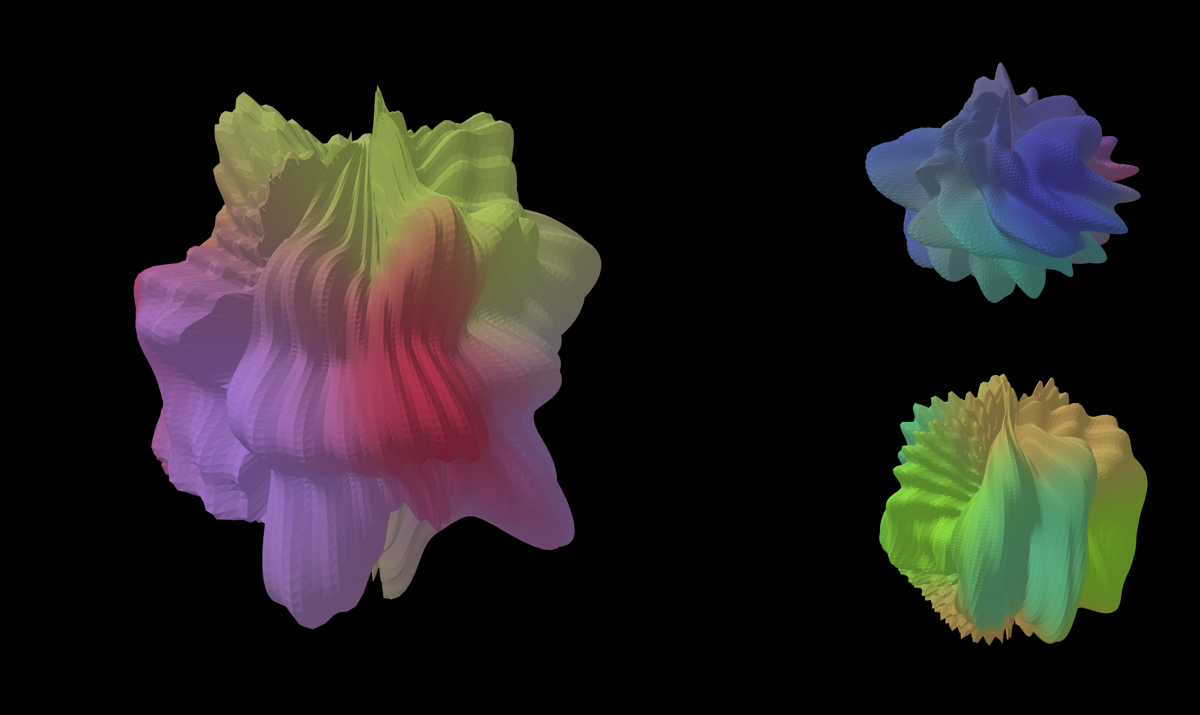

In [ ]:
#render three selected samples on a black background

fig = plt.figure(figsize=(15, 8), facecolor="black")
fig._keep_layout = True
hero_theta, hero_phi = grid(180, 100)
for index, box in zip(
    hero_indices, [(0, 0, 0.58, 1), (0.57, 0.47, 0.43, 0.53), (0.57, 0, 0.43, 0.53)]
):
    ax = fig.add_axes(box, projection="3d", facecolor="black")
    xyz = surface(Z[index], hero_theta, hero_phi, time=phase)
    rgb = surface_colors(Z[index], hero_theta, hero_phi)
    plot_surface(ax, xyz, rgb, limits=np.max(np.abs(xyz)) * 1.05)
    ax.set_box_aspect((1, 1, 1), zoom=1.4)
save_plot(fig, 'hero.png')


## Genotype input

The heat map shows a small section of the dosage matrix. Below it, I plot every selected site for one person against its position on chromosome 22.

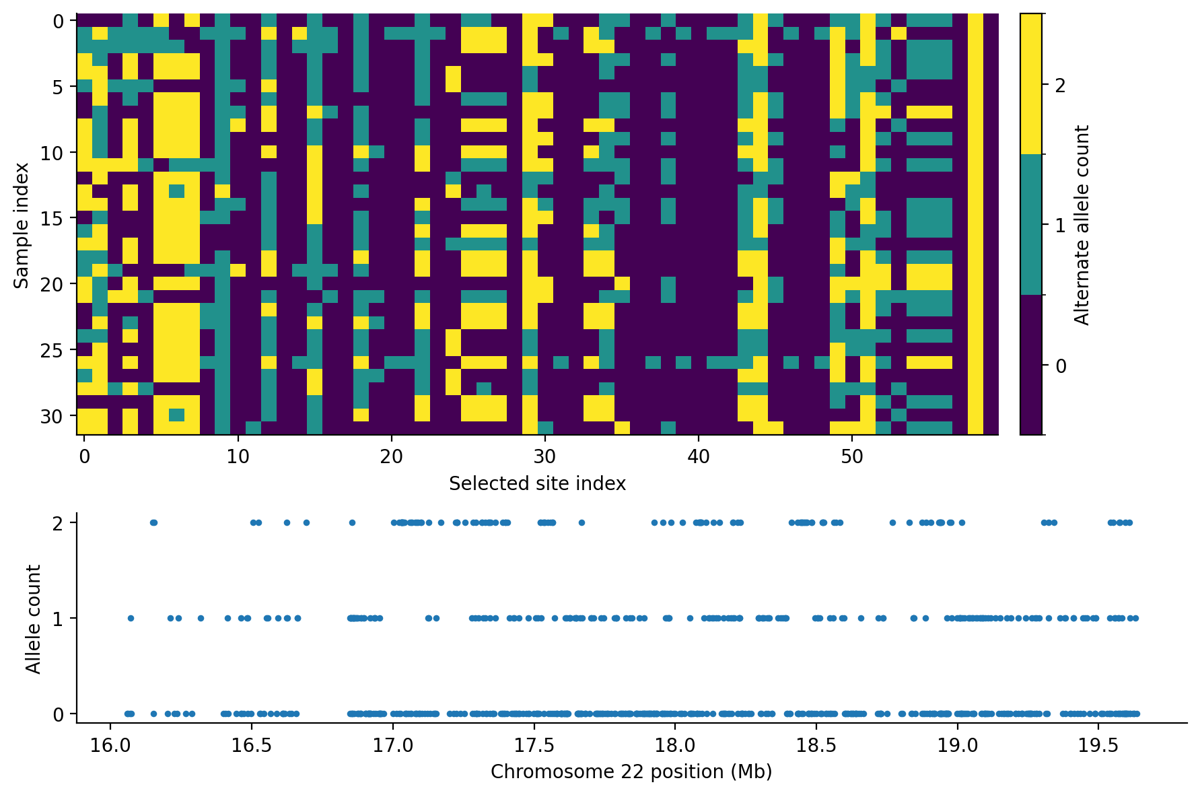

In [ ]:
#plot the dosage matrix and one sample along chromosome 22

fig, axes = plt.subplots(2, 1, figsize=(9, 6), gridspec_kw={"height_ratios": [2, 1]})
cmap = ListedColormap(["#440154", "#21918c", "#fde725"])
cmap.set_bad("0.75")
im = axes[0].imshow(
    np.ma.masked_invalid(Graw[:32, :60]),
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3),
)
axes[0].set(xlabel="Selected site index", ylabel="Sample index")
fig.colorbar(im, ax=axes[0], ticks=[0, 1, 2], label="Alternate allele count", pad=0.02)
axes[1].scatter(positions / 1e6, Graw[sample_index], s=6)
axes[1].set(xlabel="Chromosome 22 position (Mb)", ylabel="Allele count", yticks=[0, 1, 2])
save_plot(fig, 'input.png')


## Autoencoder and PCA

I compare the autoencoder with twelve-component PCA using the SVD of the centered input. Both compress 768 values into twelve. The lower plots compare their reconstructions and residuals for the same sample.

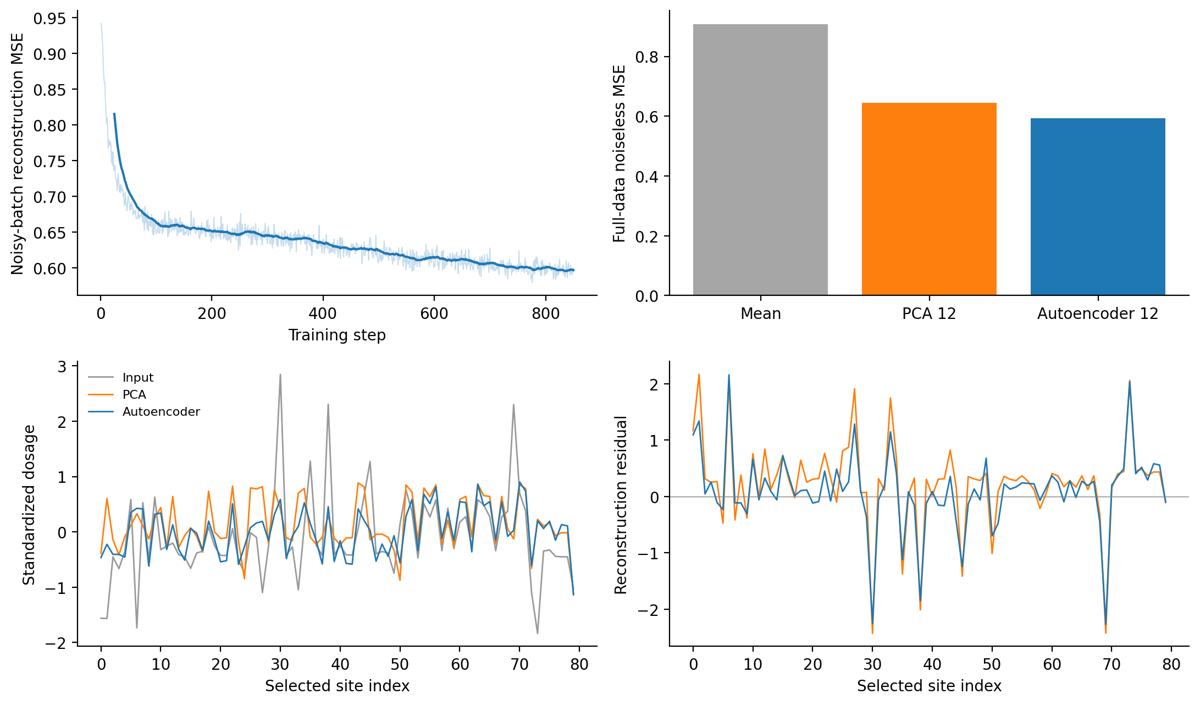

In [ ]:
#compare reconstruction error with a twelve-component pca baseline

x_center = X.mean(axis=0, keepdims=True)
_, _, vt = np.linalg.svd(X - x_center, full_matrices=False)
pca_reconstruction = ((X - x_center) @ vt[:12].T) @ vt[:12] + x_center
network_reconstruction = model.forward(X)[0]
model_mse = [
    float(np.mean((X - x_center) ** 2)),
    float(np.mean((X - pca_reconstruction) ** 2)),
    float(np.mean((X - network_reconstruction) ** 2)),
]
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5))
steps = np.arange(1, len(losses) + 1)
ax = axs[0, 0]
ax.plot(steps, losses[:, 1], alpha=0.25, linewidth=0.7)
ax.plot(steps[24:], np.convolve(losses[:, 1], np.ones(25) / 25, mode="valid"), color="C0")
ax.set(xlabel="Training step", ylabel="Noisy-batch reconstruction MSE")
ax = axs[0, 1]
ax.bar(["Mean", "PCA 12", "Autoencoder 12"], model_mse, color=["0.65", "C1", "C0"])
ax.set(ylabel="Full-data noiseless MSE")
ax = axs[1, 0]
n = 80
ax.plot(X[sample_index, :n], label="Input", color="0.6", linewidth=1)
ax.plot(pca_reconstruction[sample_index, :n], label="PCA", color="C1", linewidth=1)
ax.plot(reconstructed[:n], label="Autoencoder", color="C0", linewidth=1)
ax.set(xlabel="Selected site index", ylabel="Standardized dosage")
ax.legend(frameon=False, fontsize=8)
ax = axs[1, 1]
ax.plot(
    pca_reconstruction[sample_index, :n] - X[sample_index, :n],
    label="PCA",
    color="C1",
    linewidth=1,
)
ax.plot(reconstructed[:n] - X[sample_index, :n], label="Autoencoder", color="C0", linewidth=1)
ax.axhline(0, color="0.5", linewidth=0.5)
ax.set(xlabel="Selected site index", ylabel="Reconstruction residual")
save_plot(fig, 'compression.png')
experiment_results["model_comparison"] = {
    "models": ["mean", "PCA_12", "autoencoder_12"],
    "noiseless_full_data_mse": model_mse,
    "evaluation": "same fitting data, no held-out claim",
}
del pca_reconstruction, network_reconstruction, vt


## Bounding the amplitudes

I compare the raw latent values with RMS normalization followed by softsign.

$$u=\frac{z}{\operatorname{RMS}(z)+10^{-9}},\qquad b=\frac{u}{1+|u|}$$

Only the eight broad-wave and pleat amplitudes change between treatments. I keep the phase controls, frequencies, and deformation terms fixed. Both columns use the same camera and scale. The printed radius minima show where the raw amplitudes produce negative radii.

[
  {
    "sample": "HG00096",
    "raw": true,
    "minimum_radius": -0.1172637331746916,
    "negative_radius_vertices": 13
  },
  {
    "sample": "HG00096",
    "raw": false,
    "minimum_radius": 0.6435655722207647,
    "negative_radius_vertices": 0
  },
  {
    "sample": "HG00610",
    "raw": true,
    "minimum_radius": -0.21421366793470079,
    "negative_radius_vertices": 22
  },
  {
    "sample": "HG00610",
    "raw": false,
    "minimum_radius": 0.7664608997254937,
    "negative_radius_vertices": 0
  }
]


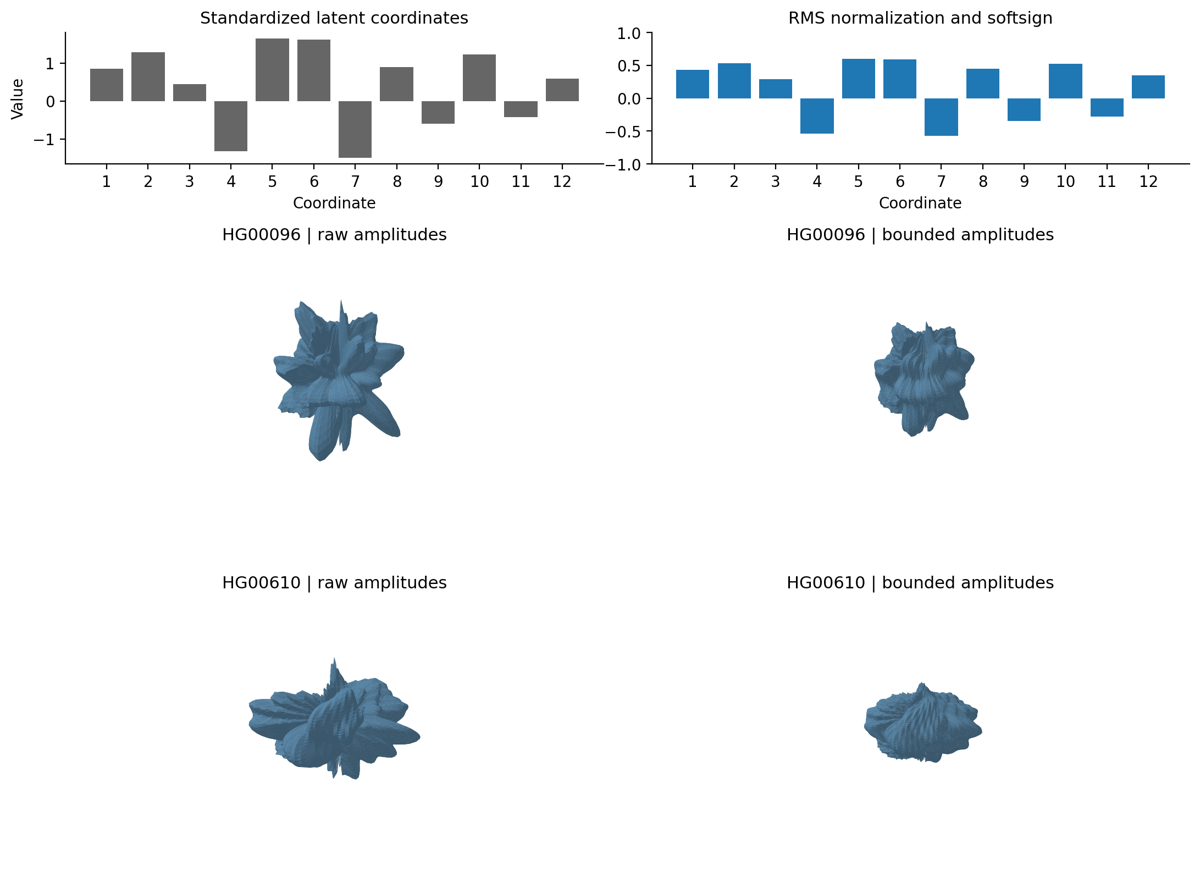

In [ ]:
#compare raw and bounded amplitudes at the same scale and count negative radii

comparison_indices = [0, 250]
fig = plt.figure(figsize=(11, 8))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 2, 2])
raw_bars = fig.add_subplot(gs[0, 0])
bounded_bars = fig.add_subplot(gs[0, 1])
raw_bars.bar(np.arange(1, 13), z, color="0.4")
bounded_bars.bar(np.arange(1, 13), np.concatenate(coefficients(z)), color="C0")
for ax, title in [
    (raw_bars, "Standardized latent coordinates"),
    (bounded_bars, "RMS normalization and softsign"),
]:
    ax.set(title=title, xlabel="Coordinate", xticks=range(1, 13))
raw_bars.set_ylabel("Value")
bounded_bars.set_ylim(-1, 1)
amplitude_pairs = [
    [surface(Z[i], T, P, time=phase, raw_amplitudes=raw) for raw in [True, False]]
    for i in comparison_indices
]
common_limit = max(np.max(np.abs(x)) for pair in amplitude_pairs for x in pair) * 1.05
amplitude_report = []
for row, index in enumerate(comparison_indices):
    for col, raw in enumerate([True, False]):
        ax = fig.add_subplot(gs[row + 1, col], projection="3d")
        plot_surface(ax, amplitude_pairs[row][col], limits=common_limit)
        ax.set_title(f'{sample_ids[index]} | {"raw" if raw else "bounded"} amplitudes')
        broad, pleats, fine, _, _ = surface_terms(Z[index], T, P, phase, raw)
        radius = 1.25 + 0.28 * broad.sum(axis=0) + 0.11 * pleats.sum(axis=0) + 0.035 * fine
        amplitude_report.append(
            {
                "sample": str(sample_ids[index]),
                "raw": raw,
                "minimum_radius": float(radius.min()),
                "negative_radius_vertices": int((radius < 0).sum()),
            }
        )
experiment_results["amplitude_comparison"] = amplitude_report
save_plot(fig, 'amplitude_bounds.png')
print(json.dumps(amplitude_report, indent=2))


## Sphere and one wave

I keep one broad-wave term active to follow its effect from the equatorial radius curve to the polar section and surface. The faint wireframe shows the starting sphere. This term has no latitude envelope in the original equations.

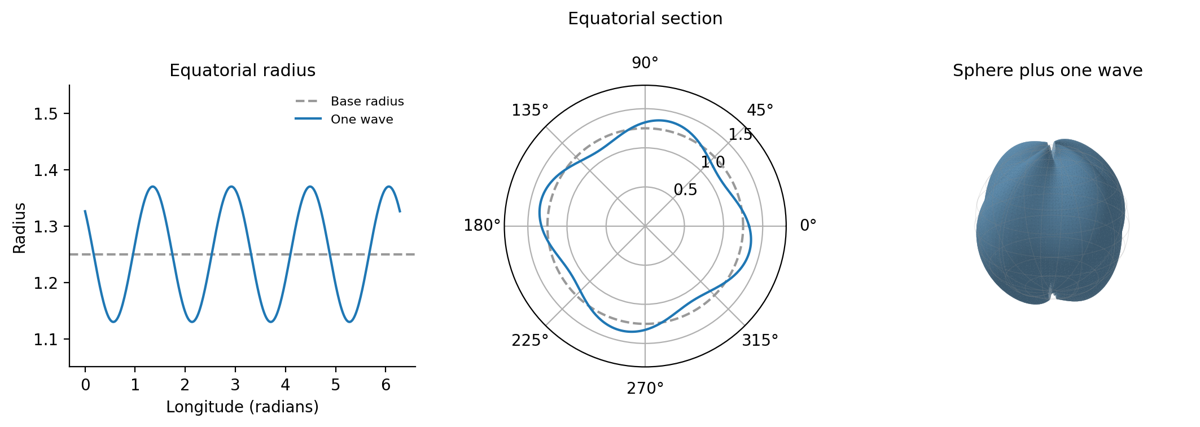

In [ ]:
#follow one radial wave from the equatorial curve to the surface

theta = np.linspace(0, 2 * np.pi, 361)
phi = np.zeros_like(theta)
r = 1.25 + 0.28 * surface_terms(z, theta, phi, phase)[0][0]
fig = plt.figure(figsize=(11, 3.7))
ax = fig.add_subplot(131)
ax.axhline(1.25, color="0.6", ls="--", label="Base radius")
ax.plot(theta, r, label="One wave")
ax.set(xlabel="Longitude (radians)", ylabel="Radius", ylim=(1.05, 1.55))
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Equatorial radius")
ax = fig.add_subplot(132, projection="polar")
ax.set_title("Equatorial section", pad=20)
ax.plot(theta, np.full_like(theta, 1.25), "--", color="0.6")
ax.plot(theta, r)
ax.set_ylim(0, 1.8)
ax.set_rticks([0.5, 1.0, 1.5])
ax.set_rlabel_position(45)
ax = fig.add_subplot(133, projection="3d")
xyz = surface(z, T, P, stage=1, time=phase)
plot_surface(ax, xyz, limits=1.65)
sphere = surface(z, T, P, stage=0, time=phase)
ax.plot_wireframe(
    *np.moveaxis(sphere, -1, 0), rstride=6, cstride=10, color="0.55", alpha=0.22, linewidth=0.4
)
ax.set_title("Sphere plus one wave")
save_plot(fig, 'wave_to_surface.png')


## Wave profiles

I compare sine, triangle, flattened sine, and exponential profiles with the same base radius, amplitude, and frequency. The exponential is normalized to [−1, 1]. For this comparison, I multiply each profile by cos²φ so it vanishes at the poles.

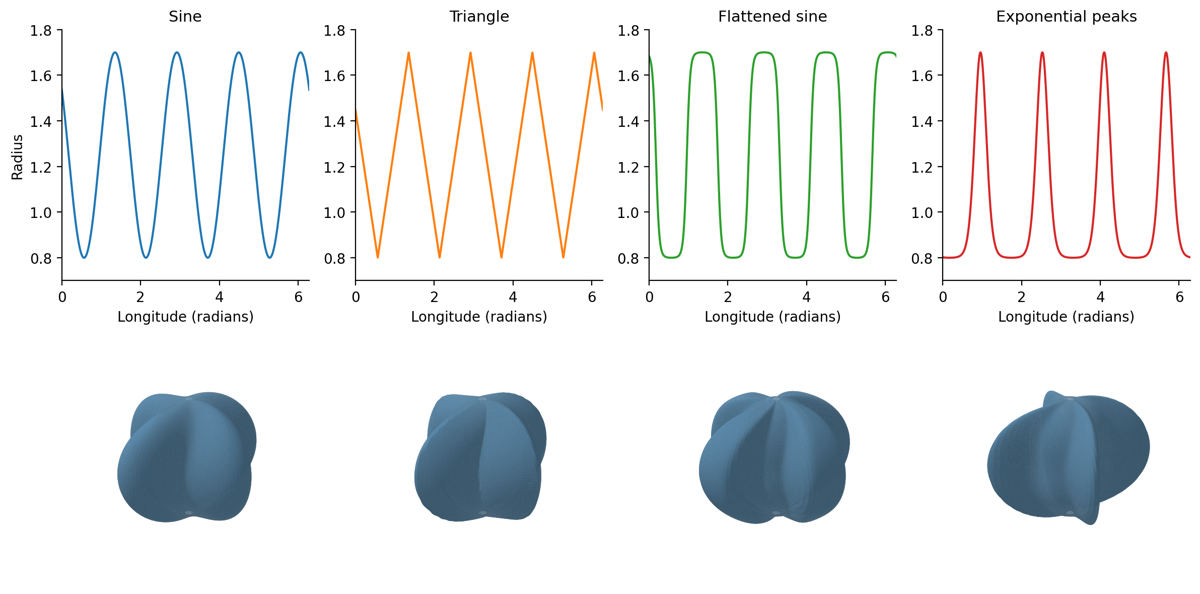

In [ ]:
#compare four wave profiles using the same radius, amplitude, and latitude envelope

def candidate_waves(u):
    return [
        np.sin(u),
        2 / np.pi * np.arcsin(np.sin(u)),
        np.tanh(3 * np.sin(u)) / np.tanh(3),
        2 * (np.exp(3 * (np.cos(u) - 1)) - np.exp(-6)) / (1 - np.exp(-6)) - 1,
    ]


ct, cp = grid(160, 82)
freq = frequencies(z)[0]
u = freq * ct + 1.7 * np.cos(cp) + 2 * np.pi * phase
theta = np.linspace(0, 2 * np.pi, 801)
profiles = candidate_waves(freq * theta + 1.7 + 2 * np.pi * phase)
fig = plt.figure(figsize=(12, 6))
for i, (field, profile) in enumerate(zip(candidate_waves(u), profiles)):
    ax = fig.add_subplot(2, 4, i + 1)
    ax.plot(theta, 1.25 + 0.45 * profile, color=f"C{i}")
    ax.set_title(["Sine", "Triangle", "Flattened sine", "Exponential peaks"][i])
    ax.set(xlim=(0, 2 * np.pi), ylim=(0.7, 1.8), xlabel="Longitude (radians)")
    if i == 0:
        ax.set_ylabel("Radius")
    radius = 1.25 + 0.45 * field * np.cos(cp) ** 2
    assert radius.min() > 0
    ax = fig.add_subplot(2, 4, i + 5, projection="3d")
    plot_surface(ax, radial_xyz(radius, ct, cp), limits=1.8)
save_plot(fig, 'equation_tests.png')
experiment_results["equations"] = {
    "families": ["sine", "triangle", "tanh_sine", "exponential_peak"],
    "radial_amplitude": 0.45,
    "frequency": int(freq),
}


## Pleat strength

I try pleat weights of 0, 0.11, and 0.44 on two records. The broad-wave and fine-ripple weights stay at 0.28 and 0.035. Each row uses the same sample, and all views share a scale.

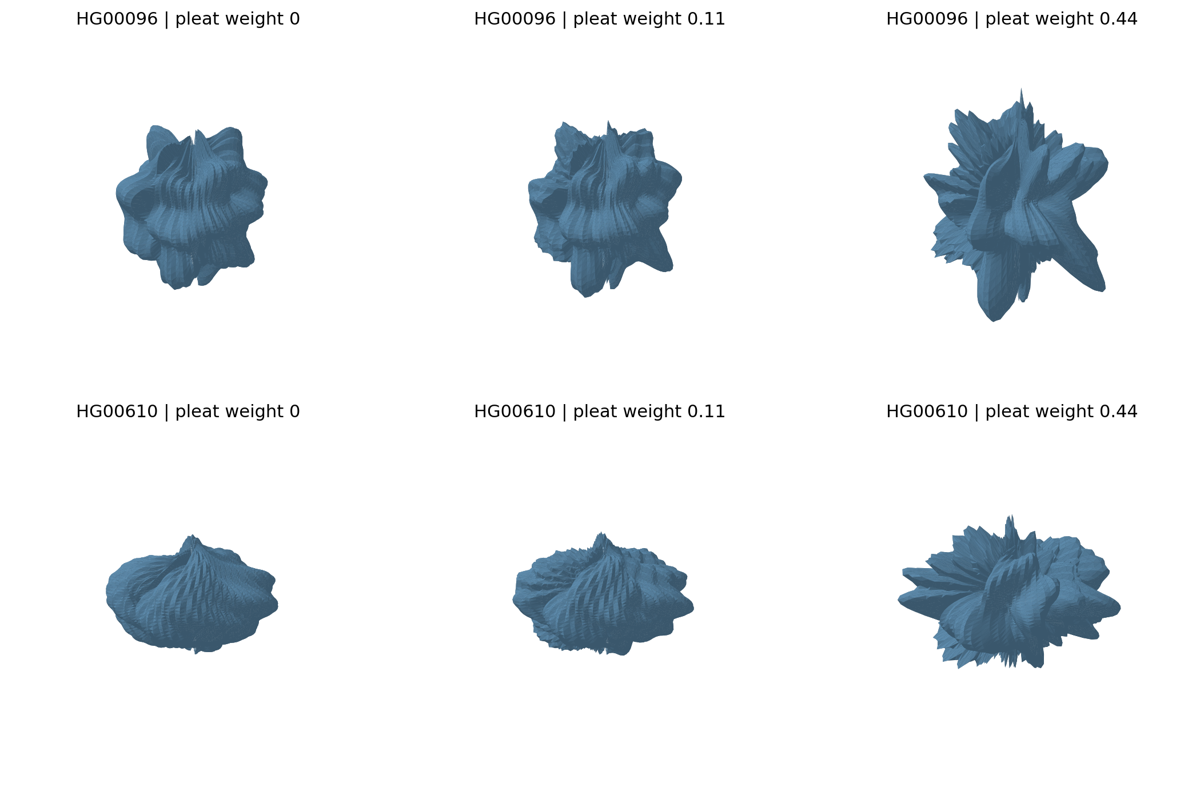

In [ ]:
#compare pleat strength across two genotype samples

weights = [0, 0.11, 0.44]
comparison_indices = [0, 250]
surfaces = [
    [surface(Z[index], T, P, time=phase, pleat_weight=w) for w in weights]
    for index in comparison_indices
]
limit = max(np.abs(xyz).max() for row in surfaces for xyz in row) * 1.04

fig = plt.figure(figsize=(11, 7))
for row, group in enumerate(surfaces):
    for col, xyz in enumerate(group):
        ax = fig.add_subplot(2, 3, row * 3 + col + 1, projection="3d")
        plot_surface(ax, xyz, limits=limit)
        ax.set_title(f"{sample_ids[comparison_indices[row]]} | pleat weight {weights[col]:g}")
save_plot(fig, 'fold_balance.png')
experiment_results["fold_balance"] = {
    "sample_indices": comparison_indices,
    "pleat_weights": weights,
}


## Latent sensitivity

I change one coordinate at a time by −0.1 and +0.1, then measure displacement at corresponding vertices.

$$d_{\mathrm{RMS}}=\sqrt{\frac{1}{N}\sum_i\|v_i'-v_i\|^2}$$

The other eleven coordinates and the angular grid stay fixed. The paired bars show whether positive and negative changes have similar effects.

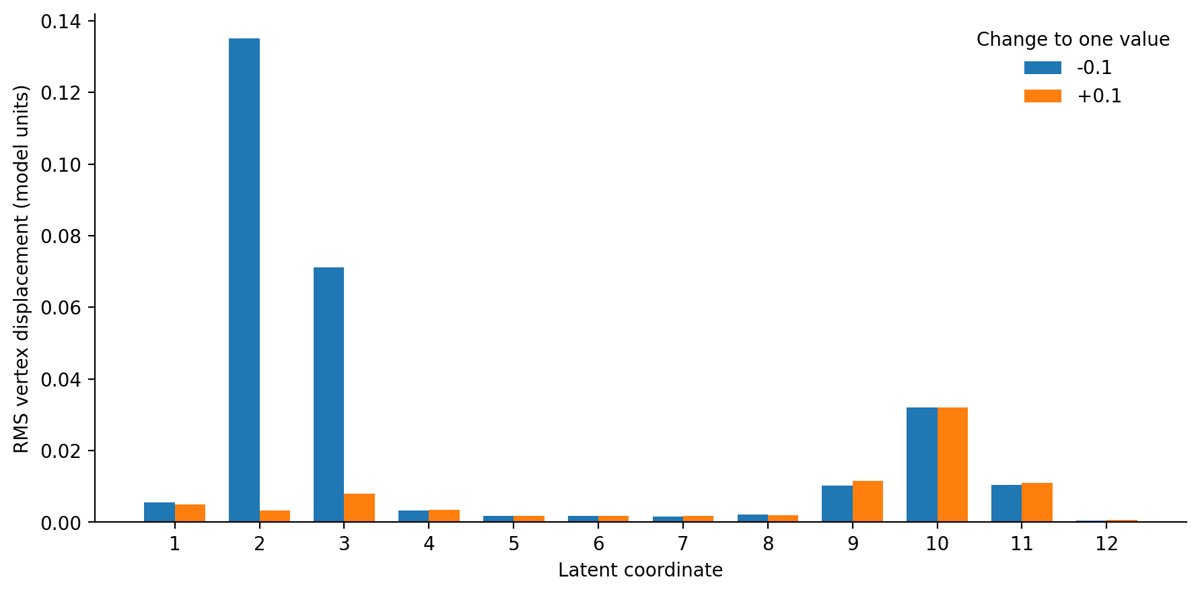

In [ ]:
#perturb each latent coordinate in both directions (+/- 0.1) and measure vertex displacement

step_size = 0.1
reference_xyz = surface(z, T, P, time=phase)
responses = np.zeros((12, 2))

for coordinate in range(12):
    for direction, change in enumerate([-step_size, step_size]):
        trial = z.copy()
        trial[coordinate] += change
        xyz = surface(trial, T, P, time=phase)
        responses[coordinate, direction] = np.sqrt(
            np.mean(np.sum((xyz - reference_xyz) ** 2, axis=-1))
        )

fig, ax = plt.subplots(figsize=(9, 4.5))
coordinates = np.arange(1, 13)
ax.bar(coordinates - 0.18, responses[:, 0], width=0.36, label="-0.1")
ax.bar(coordinates + 0.18, responses[:, 1], width=0.36, label="+0.1")
ax.set(
    xlabel="Latent coordinate",
    ylabel="RMS vertex displacement (model units)",
    xticks=coordinates,
)
ax.legend(title="Change to one value", frameon=False)
save_plot(fig, 'control_test.png')
experiment_results["control_test"] = {"step": step_size, "rms_displacement": responses.tolist()}


## Single-site edit

I change the first recorded dosage from 0 to 1 and pass the edited record through the fitted encoder. The plots show the change in all twelve latent coordinates, the displacement map, and both surfaces at the same scale.

{'site_index': 0, 'chromosome_position': 16058883, 'before': 0.0, 'after': 1.0, 'max_latent_change': 0.05012977123260498, 'mean_vertex_displacement': 0.02332524986949409, 'max_vertex_displacement': 0.06704063733567475}


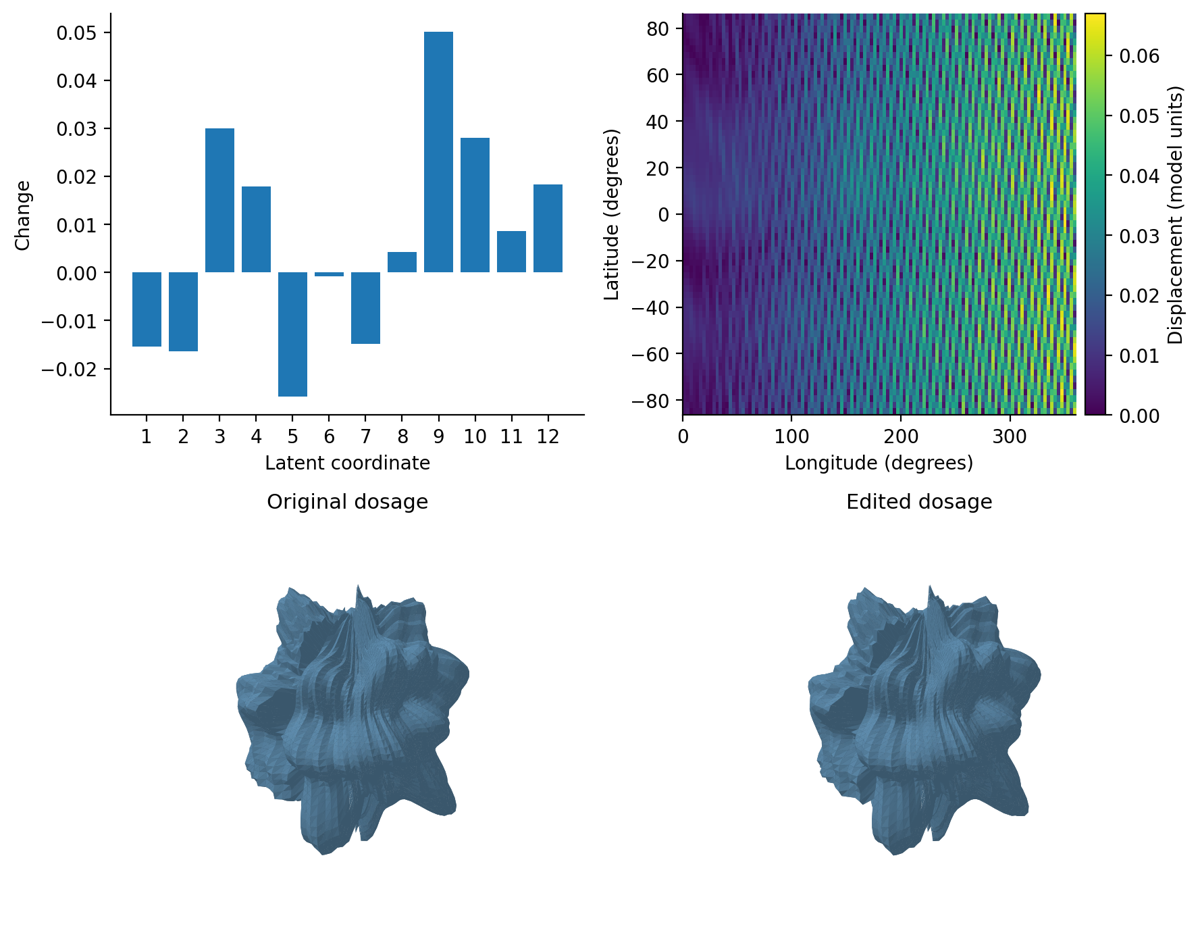

In [ ]:
#change one dosage and trace its effect on the latent values and mesh

edit_site = int(np.flatnonzero(np.isfinite(Graw[sample_index]))[0])
edited_counts = Graw[sample_index].copy()
before = float(edited_counts[edit_site])
edited_counts[edit_site] = before + 1 if before < 2 else 1
edited_z = encode_counts(edited_counts)
original_xyz = surface(z, T, P, time=phase)
edited_xyz = surface(edited_z, T, P, time=phase)
displacement = np.linalg.norm(edited_xyz - original_xyz, axis=-1)
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(221)
ax.bar(np.arange(1, 13), edited_z - z)
ax.set(xlabel="Latent coordinate", ylabel="Change", xticks=range(1, 13))
ax = fig.add_subplot(222)
im = ax.imshow(
    displacement,
    origin="lower",
    extent=[0, 360, np.degrees(P.min()), np.degrees(P.max())],
    aspect="auto",
    cmap="viridis",
    vmin=0,
)
ax.set(xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
fig.colorbar(im, ax=ax, label="Displacement (model units)", pad=0.02)
lim = max(np.abs(original_xyz).max(), np.abs(edited_xyz).max()) * 1.05
for panel, xyz in [(223, original_xyz), (224, edited_xyz)]:
    ax = fig.add_subplot(panel, projection="3d")
    plot_surface(ax, xyz, limits=lim)
    ax.set_title("Original dosage" if panel == 223 else "Edited dosage")
save_plot(fig, 'allele_edit.png')
experiment_results["allele_edit"] = {
    "site_index": edit_site,
    "chromosome_position": int(positions[edit_site]),
    "before": before,
    "after": float(edited_counts[edit_site]),
    "max_latent_change": float(np.max(np.abs(edited_z - z))),
    "mean_vertex_displacement": float(displacement.mean()),
    "max_vertex_displacement": float(displacement.max()),
}
print(experiment_results["allele_edit"])


## Random genotype

To test how much structure comes from the equations, I replace the real input with 768 independent counts from {0, 1, 2}. Those counts pass through the fitted encoder to produce the twelve controls.

Change `random_seed` in Settings and rerun this cell for another sculpture. The random counts don't preserve relationships between sites.

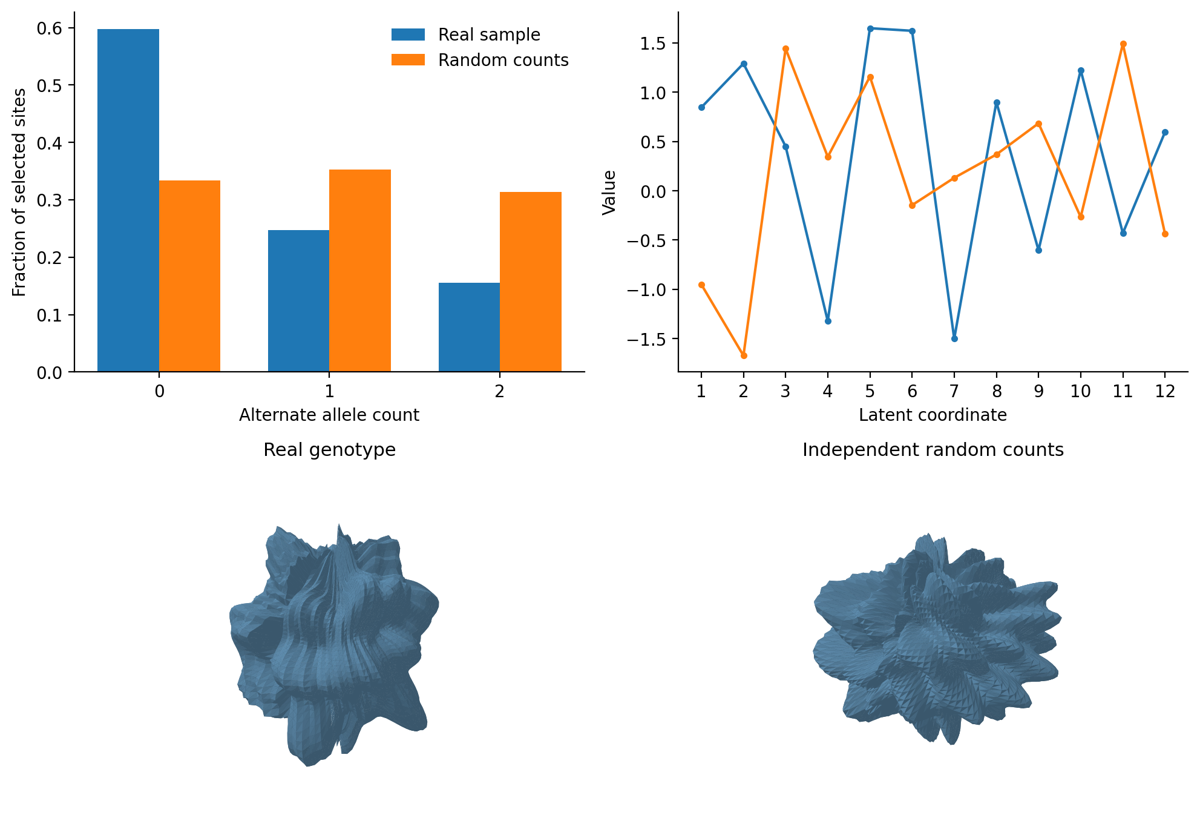

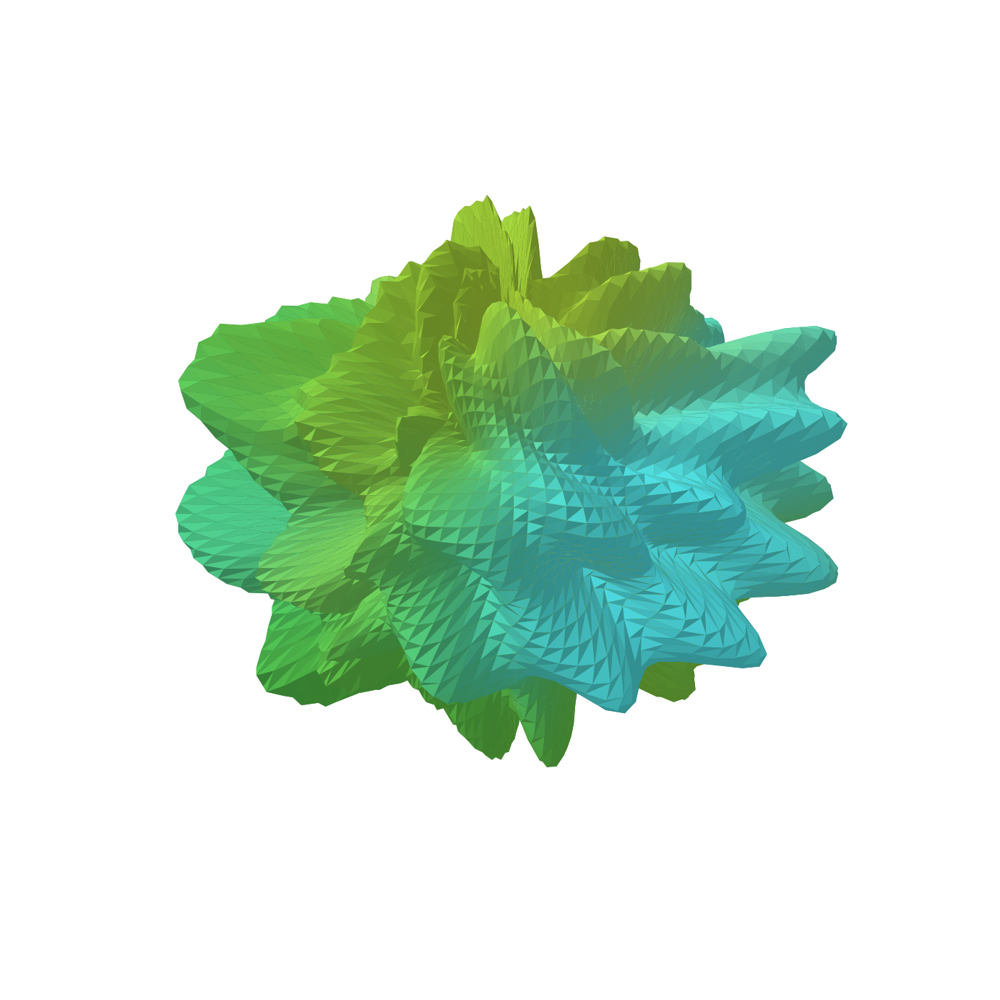

In [ ]:
#generate 768 random allele counts and pass them through the fitted model

rng = np.random.default_rng(random_seed)
random_counts = rng.integers(0, 3, size=Graw.shape[1]).astype(np.float32)
random_z = encode_counts(random_counts)
real_xyz = surface(z, T, P, time=phase)
random_xyz = surface(random_z, T, P, time=phase)
limit = max(np.abs(real_xyz).max(), np.abs(random_xyz).max()) * 1.05

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(221)
valid = Graw[sample_index][np.isfinite(Graw[sample_index])].astype(int)
real_hist = np.bincount(valid, minlength=3) / len(valid)
random_hist = np.bincount(random_counts.astype(int), minlength=3) / len(random_counts)
ax.bar(np.arange(3) - 0.18, real_hist, width=0.36, label="Real sample")
ax.bar(np.arange(3) + 0.18, random_hist, width=0.36, label="Random counts")
ax.set(xlabel="Alternate allele count", ylabel="Fraction of selected sites", xticks=[0, 1, 2])
ax.legend(frameon=False)

ax = fig.add_subplot(222)
ax.plot(np.arange(1, 13), z, "o-", label="Real sample", markersize=3)
ax.plot(np.arange(1, 13), random_z, "o-", label="Random counts", markersize=3)
ax.set(xlabel="Latent coordinate", ylabel="Value", xticks=range(1, 13))
for panel, xyz in [(223, real_xyz), (224, random_xyz)]:
    ax = fig.add_subplot(panel, projection="3d")
    plot_surface(ax, xyz, limits=limit)
    ax.set_title("Real genotype" if panel == 223 else "Independent random counts")
save_plot(fig, 'random_input.png')
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")
plot_surface(ax, random_xyz, surface_colors(random_z, T, P), limits=limit)
save_plot(fig, "random_sculpture.png")
save_npz(out / "data" / "random_sculpture.npz", counts=random_counts, latent=random_z)
experiment_results["random_input"] = {
    "seed": random_seed,
    "uniform_counts": True,
    "latent_values": random_z.tolist(),
}


## Frequency threshold

I compare z₀ = 0.9999 with z₀ = 1.0001 while holding the other coordinates fixed. In `f₁ = 2 + int(3|z₀|)`, that small change increases the frequency from four to five.

I report the RMS vertex displacement in model units and as a fraction of the 1.25 base radius.

{
  "threshold": 1.0,
  "values": [
    0.9999,
    1.0001
  ],
  "frequencies": [
    4,
    5
  ],
  "rms_jump": 0.17806608862648607,
  "fraction_of_base_radius": 0.14245287090118885
}


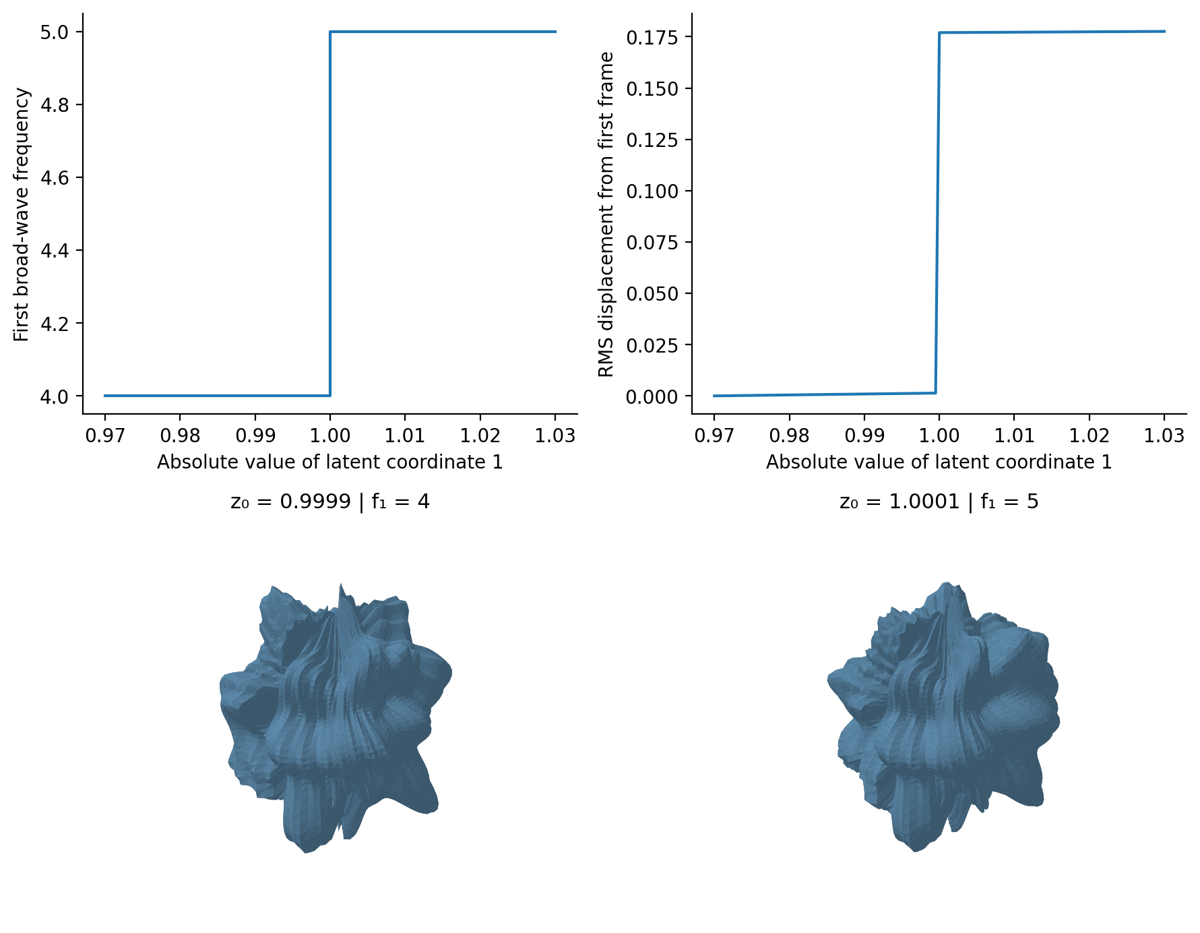

In [ ]:
#cross one integer-frequency threshold and measure the change in shape

threshold = 1.0
sign = 1
values = np.linspace(threshold - 0.03, threshold + 0.03, 121)
probe_theta, probe_phi = grid(72, 38)
anchor = z.astype(float).copy()
anchor[0] = sign * values[0]
anchor_xyz = surface(anchor, probe_theta, probe_phi, time=phase)
frequency_trace, movement_trace = [], []

for value in values:
    trial = z.astype(float).copy()
    trial[0] = sign * value
    frequency_trace.append(frequencies(trial)[0])
    xyz = surface(trial, probe_theta, probe_phi, time=phase)
    movement_trace.append(np.sqrt(np.mean(np.sum((xyz - anchor_xyz) ** 2, axis=-1))))

before, after = z.astype(float).copy(), z.astype(float).copy()
before[0], after[0] = sign * (threshold - 0.0001), sign * (threshold + 0.0001)
pair = [surface(v, T, P, time=phase) for v in [before, after]]
limit = max(np.abs(xyz).max() for xyz in pair) * 1.05
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(221)
ax.step(values, frequency_trace, where="post")
ax.set(xlabel="Absolute value of latent coordinate 1", ylabel="First broad-wave frequency")
ax = fig.add_subplot(222)
ax.plot(values, movement_trace)
ax.set(
    xlabel="Absolute value of latent coordinate 1", ylabel="RMS displacement from first frame"
)
for panel, xyz in [(223, pair[0]), (224, pair[1])]:
    ax = fig.add_subplot(panel, projection="3d")
    plot_surface(ax, xyz, limits=limit)
    ax.set_title("z₀ = 0.9999 | f₁ = 4" if panel == 223 else "z₀ = 1.0001 | f₁ = 5")
save_plot(fig, 'frequency_step.png')
experiment_results["frequency_step"] = {
    "threshold": float(threshold),
    "values": [float(before[0]), float(after[0])],
    "frequencies": [int(frequencies(before)[0]), int(frequencies(after)[0])],
    "rms_jump": float(np.sqrt(np.mean(np.sum((pair[1] - pair[0]) ** 2, axis=-1)))),
}

experiment_results["frequency_step"]["fraction_of_base_radius"] = (
    experiment_results["frequency_step"]["rms_jump"] / 1.25
)
print(json.dumps(experiment_results["frequency_step"], indent=2))


## Palette calculation

Each column uses a different genotype-derived vector to calculate its palette. I apply the palettes to identical geometry so I can compare color without changing the folds. The DCT follows the orthonormal definition in SciPy's tutorial.

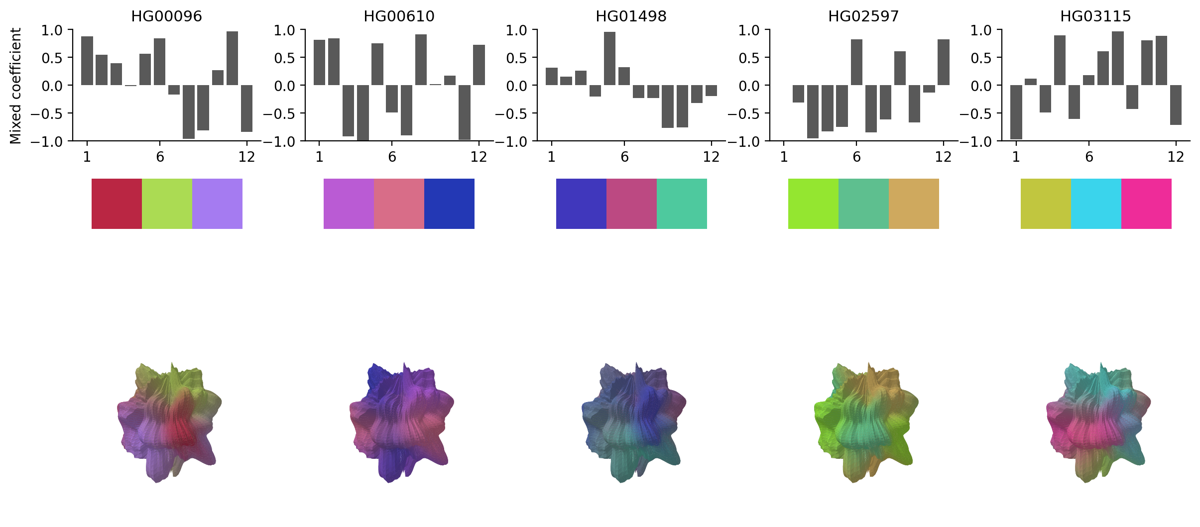

In [ ]:
#calculate palettes for several samples and apply them to the same mesh

fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(3, 5, height_ratios=[1, 0.45, 2.8])
for column, index in enumerate(chosen_indices):
    q, anchors = palette_parameters(Z[index])
    ax = fig.add_subplot(gs[0, column])
    ax.set_title(str(sample_ids[index]))
    ax.bar(np.arange(12), q, color="0.35", width=0.8)
    ax.set(ylim=(-1, 1), xticks=[0, 5, 11], xticklabels=[1, 6, 12])
    if column == 0:
        ax.set_ylabel("Mixed coefficient")
    ax = fig.add_subplot(gs[1, column])
    ax.imshow(anchors[None, :, :])
    ax.axis("off")
    ax = fig.add_subplot(gs[2, column], projection="3d")

    plot_surface(ax, final_xyz, colors=surface_colors(Z[index], T, P), limits=plot_limit)
save_plot(fig, 'palette_assignment.png')
experiment_results["color_palettes"] = {
    "sample_indices": chosen_indices,
    "rgb_anchors": [palette_parameters(Z[i])[1].tolist() for i in chosen_indices],
    "inputs": "Twelve standardized latent values only; no metadata or sample index.",
}


## Color blending

The upper maps show the three softmax weights. Below, I combine the anchors into an RGB texture and apply it to the surface. The rotated view uses the same colors.

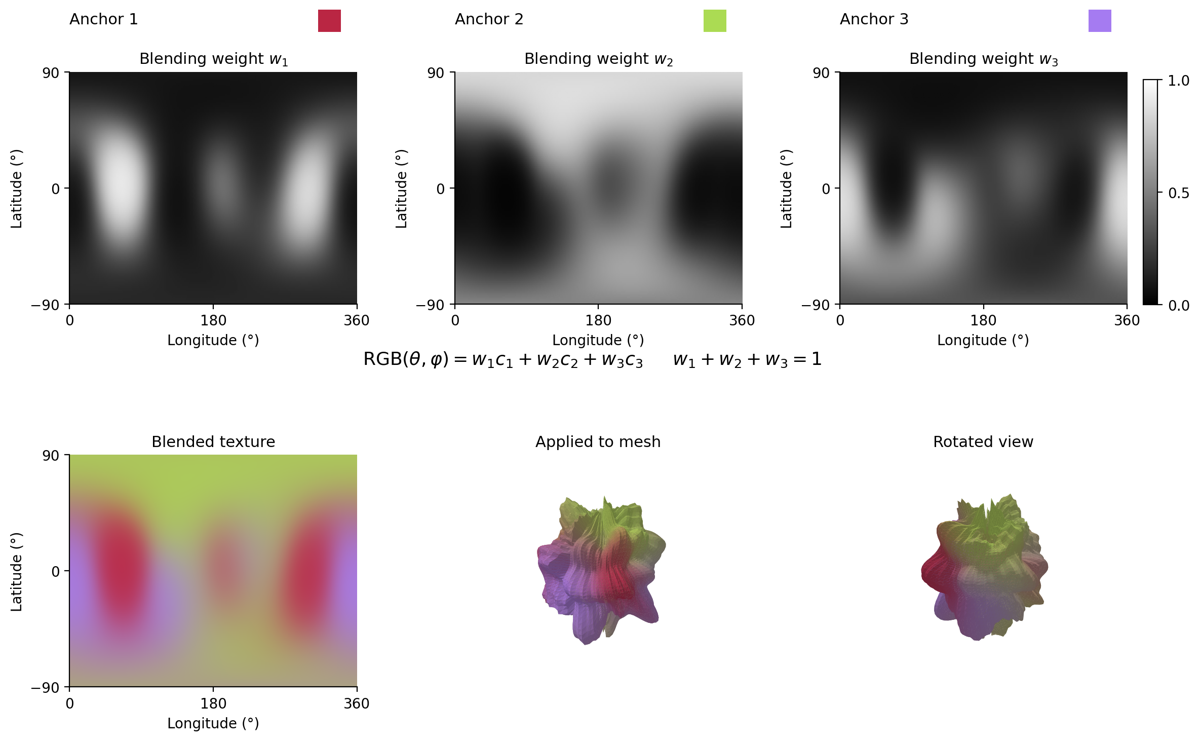

In [ ]:
#plot the blending weights, combined texture, and colored surface

map_theta, map_phi = np.meshgrid(
    np.linspace(0, 2 * np.pi, 241), np.linspace(-np.pi / 2, np.pi / 2, 121)
)
q, anchors, color_fields, fractions, texture = color_parts(z, map_theta, map_phi)
fig = plt.figure(figsize=(12, 7.4))
fig._keep_layout = True
gs = fig.add_gridspec(
    2, 3, left=0.07, right=0.94, bottom=0.06, top=0.88, hspace=0.65, wspace=0.34
)
for column in range(3):
    ax = fig.add_subplot(gs[0, column])
    im = ax.imshow(
        fractions[..., column],
        origin="lower",
        extent=[0, 360, -90, 90],
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto",
    )
    ax.set(
        title=f"Blending weight $w_{column + 1}$",
        xlabel="Longitude (°)",
        ylabel="Latitude (°)",
        xticks=[0, 180, 360],
        yticks=[-90, 0, 90],
    )
    box = ax.get_position()
    fig.text(box.x0, 0.95, f"Anchor {column + 1}", va="center", fontsize=11)
    swatch = fig.add_axes([box.x1 - 0.035, 0.933, 0.025, 0.03])
    swatch.imshow(anchors[column][None, None, :])
    swatch.axis("off")
bar_ax = fig.add_axes([0.953, 0.57, 0.012, 0.30])
fig.colorbar(im, cax=bar_ax, ticks=[0, 0.5, 1])
fig.text(
    0.50,
    0.49,
    r"$\mathrm{RGB}(\theta,\varphi)=w_1c_1+w_2c_2+w_3c_3$" "     " + r"$w_1+w_2+w_3=1$",
    ha="center",
    fontsize=13,
)
ax = fig.add_subplot(gs[1, 0])
ax.imshow(texture, origin="lower", extent=[0, 360, -90, 90], aspect="auto")
ax.set(
    title="Blended texture",
    xlabel="Longitude (°)",
    ylabel="Latitude (°)",
    xticks=[0, 180, 360],
    yticks=[-90, 0, 90],
)
for column, angle in [(1, 38), (2, 123)]:
    ax = fig.add_subplot(gs[1, column], projection="3d")
    plot_surface(ax, final_xyz, surface_colors(z, T, P), limits=plot_limit, azimuth=angle)
    ax.set_title("Applied to mesh" if column == 1 else "Rotated view")
save_plot(fig, 'color_fields.png')


## Color treatments

I compare a uniform anchor with viridis applied to the first blending fraction, then with the three-anchor mixture. Geometry, camera, and lighting stay fixed.

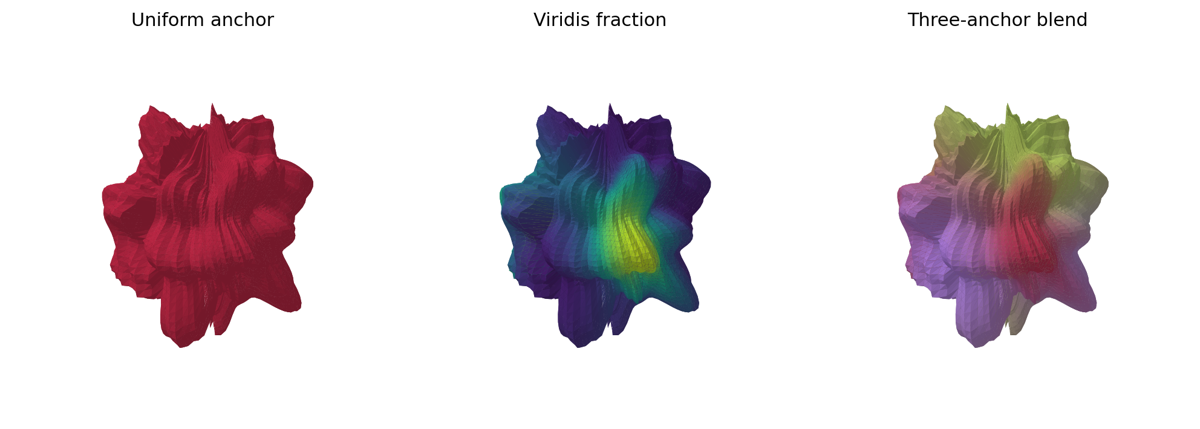

In [ ]:
#compare uniform color, viridis, and the three-anchor blend

q, anchors, color_fields, fractions, final_colors = color_parts(z, T, P)
fig = plt.figure(figsize=(10, 3.8))
alternatives = [
    np.broadcast_to(anchors[0], final_colors.shape),
    plt.get_cmap("viridis")(fractions[..., 0])[..., :3],
    final_colors,
]
for i, colors in enumerate(alternatives):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    plot_surface(ax, final_xyz, colors=colors, limits=plot_limit)
for ax, title in zip(fig.axes, ["Uniform anchor", "Viridis fraction", "Three-anchor blend"]):
    ax.set_title(title)
save_plot(fig, 'color_tests.png')


## Mesh repair

The grid stops short of both poles, leaving two open rings. Several angular terms also give different positions at longitude 0 and 2π.

I subtract the endpoint mismatch gradually over the last fifth of longitude using smoothstep. After the endpoints meet, I join them with shared vertex indices and cap each end ring with a triangle fan.

I check edge counts, Euler characteristic, triangle areas, and intersections between triangles that don't share a vertex. Shared-vertex pairs are excluded from the intersection test. The seam-gap measurement uses a separate 200-latitude probe.

This is a code reconstruction of the repair. The earlier prints also had manual Blender edits, which aren't reproduced here. The exported meshes still need inspection before printing.

{
  "vertices": 7442,
  "triangles": 14880,
  "boundary_edges": 0,
  "nonmanifold_edges": 0,
  "euler_characteristic": 2,
  "minimum_triangle_area": 8.864073565552565e-05,
  "nonadjacent_intersecting_pairs": 0,
  "repair_grid_seam_gap": 0.5683625226281428,
  "maximum_original_seam_gap": 0.5886576113750537,
  "seam_probe_latitude_samples": 200
}


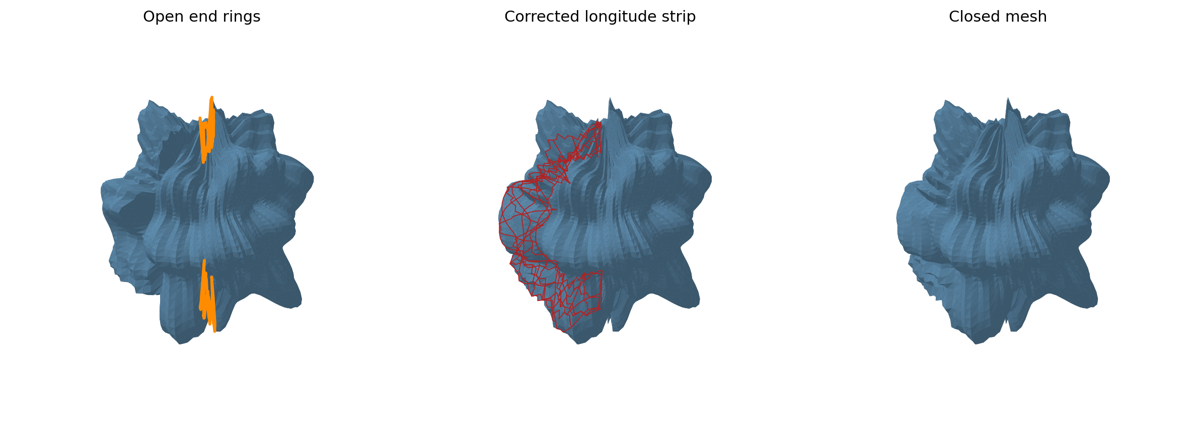

In [ ]:
#close the seam and end rings, then check topology and nonadjacent triangle intersections

def edge_counts(faces):
    edges = np.concatenate([faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]])
    return np.unique(np.sort(edges, axis=1), axis=0, return_counts=True)


def close_mesh(vector, nt=120, nphi=62):
    theta, phi = np.meshgrid(
        np.linspace(0, 2 * np.pi, nt + 1),
        np.linspace(-0.96 * np.pi / 2, 0.96 * np.pi / 2, nphi),
    )
    original = surface(vector, theta, phi, time=phase)
    mismatch = original[:, -1] - original[:, 0]
    u = np.clip((theta / (2 * np.pi) - 0.8) / 0.2, 0, 1)
    blend = u * u * (3 - 2 * u)
    corrected = original - blend[..., None] * mismatch[:, None, :]
    assert np.allclose(corrected[:, -1], corrected[:, 0], atol=1e-12)

    corrected = corrected[:, :-1]
    vertices = corrected.reshape(-1, 3)
    faces = triangles(nphi, nt)
    bottom, top = len(vertices), len(vertices) + 1
    vertices = np.vstack([vertices, corrected[0].mean(axis=0), corrected[-1].mean(axis=0)])
    caps = []
    for col in range(nt):
        following = (col + 1) % nt
        caps.extend(
            [
                (bottom, col, following),
                (top, (nphi - 1) * nt + following, (nphi - 1) * nt + col),
            ]
        )
    faces = np.vstack([faces, np.array(caps, dtype=np.int32)])
    tri = vertices[faces]
    volume = np.einsum("ij,ij->i", tri[:, 0], np.cross(tri[:, 1], tri[:, 2])).sum() / 6
    if volume < 0:
        faces = faces[:, [0, 2, 1]]
    return vertices, faces, corrected, mismatch


def mesh_report(vertices, faces):
    edges, counts = edge_counts(faces)
    tri = vertices[faces]
    area = np.linalg.norm(np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]), axis=1) / 2
    return {
        "vertices": len(vertices),
        "triangles": len(faces),
        "boundary_edges": int((counts == 1).sum()),
        "nonmanifold_edges": int((counts > 2).sum()),
        "euler_characteristic": int(len(vertices) - len(edges) + len(faces)),
        "minimum_triangle_area": float(area.min()),
    }


def nonadjacent_intersections(vertices, faces, tolerance=1e-10):

    tri = vertices[faces]
    lo, hi = tri.min(axis=1), tri.max(axis=1)
    order = np.argsort(lo[:, 0])
    ordered_low = lo[order, 0]
    pairs = []
    for rank, i in enumerate(order):
        stop = np.searchsorted(ordered_low, hi[i, 0] + tolerance, side="right")
        candidates = order[rank + 1 : stop]
        overlap = np.all(hi[candidates] >= lo[i] - tolerance, axis=1)
        overlap &= np.all(lo[candidates] <= hi[i] + tolerance, axis=1)
        candidates = candidates[overlap]

        # ignore expected contact at shared vertices
        shared = (faces[candidates, :, None] == faces[i][None, None, :]).any(axis=(1, 2))
        candidates = candidates[~shared]
        if not len(candidates):
            continue
        first, second = tri[i], tri[candidates]
        e1 = np.roll(first, -1, axis=0) - first
        e2 = np.roll(second, -1, axis=1) - second
        n1, n2 = np.cross(e1[0], e1[1]), np.cross(e2[:, 0], e2[:, 1])
        axes = np.concatenate(
            [
                np.broadcast_to(n1, (len(second), 1, 3)),
                n2[:, None, :],
                np.cross(e1[None, :, None, :], e2[:, None, :, :]).reshape(-1, 9, 3),
                np.broadcast_to(np.cross(n1, e1), (len(second), 3, 3)),
                np.cross(n2[:, None, :], e2),
            ],
            axis=1,
        )
        norm = np.linalg.norm(axes, axis=-1, keepdims=True)
        axes /= np.where(norm > tolerance, norm, 1)
        p1 = np.einsum("vj,baj->bav", first, axes)
        p2 = np.einsum("bvj,baj->bav", second, axes)
        separated = (
            (p1.max(axis=2) < p2.min(axis=2) - tolerance)
            | (p2.max(axis=2) < p1.min(axis=2) - tolerance)
        ).any(axis=1)
        pairs.extend((int(i), int(j)) for j in candidates[~separated])
    return np.array(pairs, dtype=int).reshape(-1, 2)


test_faces = np.array([[0, 1, 2], [3, 4, 5]])
test_first = np.array([[0.0, 0, 0], [2, 0, 0], [0, 2, 0]])
for test_second, expected in [
    (np.array([[0.4, 0.4, -1], [0.4, 0.4, 1], [0.8, 0.4, 0]]), 1),
    (np.array([[3.0, 3, 0], [4, 3, 0], [3, 4, 0]]), 0),
    (np.array([[0.2, 0.2, 0], [0.6, 0.2, 0], [0.2, 0.6, 0]]), 1),
]:
    hits = nonadjacent_intersections(np.vstack([test_first, test_second]), test_faces)
    assert len(hits) == expected


repaired_vertices, repaired_faces, corrected, seam_delta = close_mesh(z)
repair_report = mesh_report(repaired_vertices, repaired_faces)
assert repair_report["boundary_edges"] == repair_report["nonmanifold_edges"] == 0
assert repair_report["euler_characteristic"] == 2
assert repair_report["minimum_triangle_area"] > 1e-12
intersection_pairs = nonadjacent_intersections(repaired_vertices, repaired_faces)
repair_report["nonadjacent_intersecting_pairs"] = len(intersection_pairs)
repair_report["repair_grid_seam_gap"] = float(np.linalg.norm(seam_delta, axis=1).max())

seam_probe_phi = np.linspace(-0.96 * np.pi / 2, 0.96 * np.pi / 2, 200)
seam_start = surface(z, np.zeros(200), seam_probe_phi, time=phase)
seam_end = surface(z, np.full(200, 2 * np.pi), seam_probe_phi, time=phase)
repair_report["maximum_original_seam_gap"] = float(
    np.linalg.norm(seam_end - seam_start, axis=1).max()
)
repair_report["seam_probe_latitude_samples"] = 200
experiment_results["mesh_repair"] = repair_report
np.save(out / "meshes" / "intersection_pairs.npy", intersection_pairs)
print(json.dumps(repair_report, indent=2))

fig = plt.figure(figsize=(12, 4.8))
for panel in range(3):
    ax = fig.add_subplot(1, 3, panel + 1, projection="3d", computed_zorder=False)
    xyz = final_xyz if panel == 0 else corrected
    plot_surface(ax, xyz, limits=plot_limit)
    if panel == 0:
        for ring in [xyz[0], xyz[-1]]:
            loop = np.vstack([ring, ring[0]])
            ax.plot(*loop.T, color="darkorange", linewidth=2, zorder=10)
        ax.set_title("Open end rings")
    elif panel == 1:
        strip = xyz[:, int(0.8 * xyz.shape[1]) :]
        ax.plot_wireframe(
            *np.moveaxis(strip, -1, 0),
            color="firebrick",
            rstride=5,
            cstride=4,
            linewidth=0.65,
            zorder=10
        )
        ax.set_title("Corrected longitude strip")
    else:
        ax.collections[0].remove()
        tri = repaired_vertices[repaired_faces[:, [0, 2, 1]]]
        ax.add_collection3d(
            Poly3DCollection(
                tri,
                facecolors=face_shading(tri)[:, None] * np.array([0.37, 0.55, 0.68]),
                edgecolors="none",
                linewidths=0,
            )
        )
        ax.set_title("Closed mesh")
save_plot(fig, 'mesh_repair.png')


## Mesh resolution

I compare 36 × 20, 72 × 38, and 180 × 100 grids with the same equations and camera.

For $n_\theta$ longitude samples and $n_\varphi$ latitude rows, the side mesh contains $2n_\theta(n_\varphi-1)$ triangles. These counts exclude the end caps.

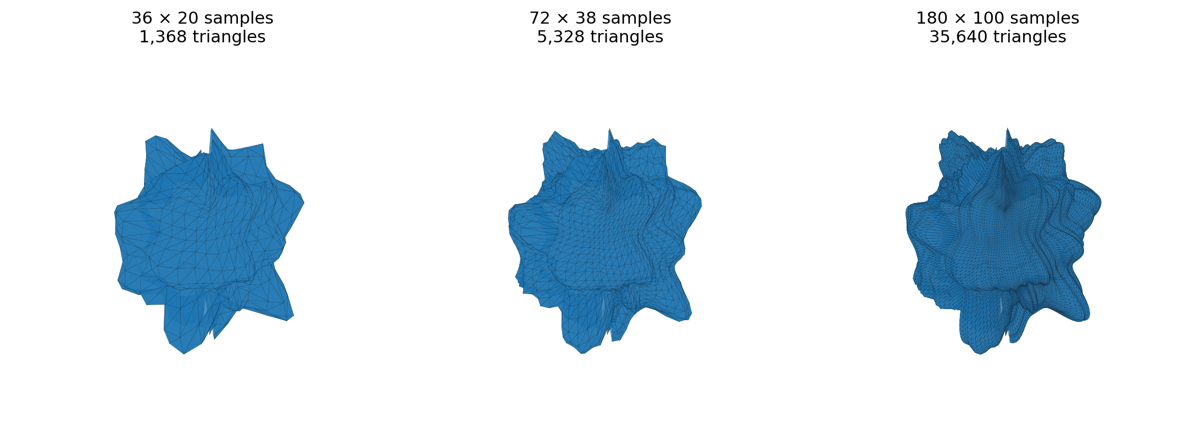

In [ ]:
#compare the same surface at three mesh resolutions

resolutions = [(36, 20), (72, 38), (180, 100)]
fig = plt.figure(figsize=(11, 4.5))
triangle_counts = []
for panel, (nt, np_) in enumerate(resolutions):
    tt, pp = grid(nt, np_)
    xyz = surface(z, tt, pp, time=phase)
    faces = triangles(np_, nt)
    triangle_counts.append(len(faces))
    ax = fig.add_subplot(1, 3, panel + 1, projection="3d")
    ax.add_collection3d(
        Poly3DCollection(
            xyz.reshape(-1, 3)[faces],
            facecolors=(0.12, 0.47, 0.71, 0.8),
            edgecolors=(0.1, 0.15, 0.2, 0.4),
            linewidths=0.18,
        )
    )
    ax.set(
        xlim=(-plot_limit, plot_limit),
        ylim=(-plot_limit, plot_limit),
        zlim=(-plot_limit, plot_limit),
    )
    ax.set_box_aspect((1, 1, 1), zoom=1.12)
    ax.view_init(24, 38)
    ax.set_axis_off()
    ax.set_title(f"{nt} × {np_} samples\n{len(faces):,} triangles")
save_plot(fig, 'resolution.png')
experiment_results["resolution"] = {"grids": resolutions, "triangle_counts": triangle_counts}


## Construction video

The animation adds each geometric term before calculating and blending the colors. I interpolate between the calculated surfaces while keeping the latent vector fixed. After an 85° rotation, the view zooms out to 100 genotype samples.

The video has 800 frames at 20 fps. I render the grid once and crop it during the zoom to avoid redrawing all 100 objects for every frame. The input records and latent vectors are saved with the video.

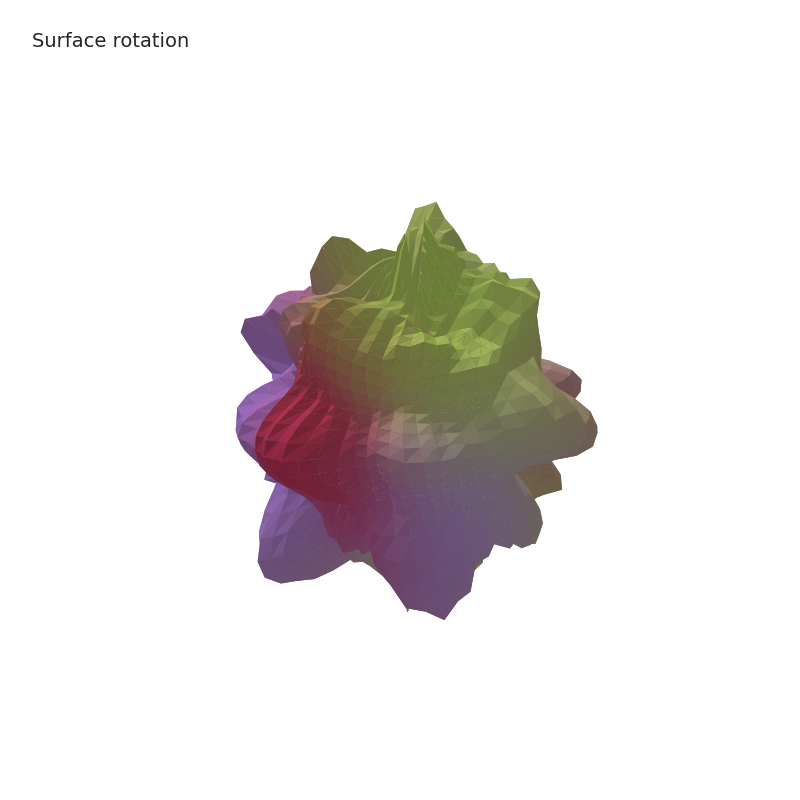

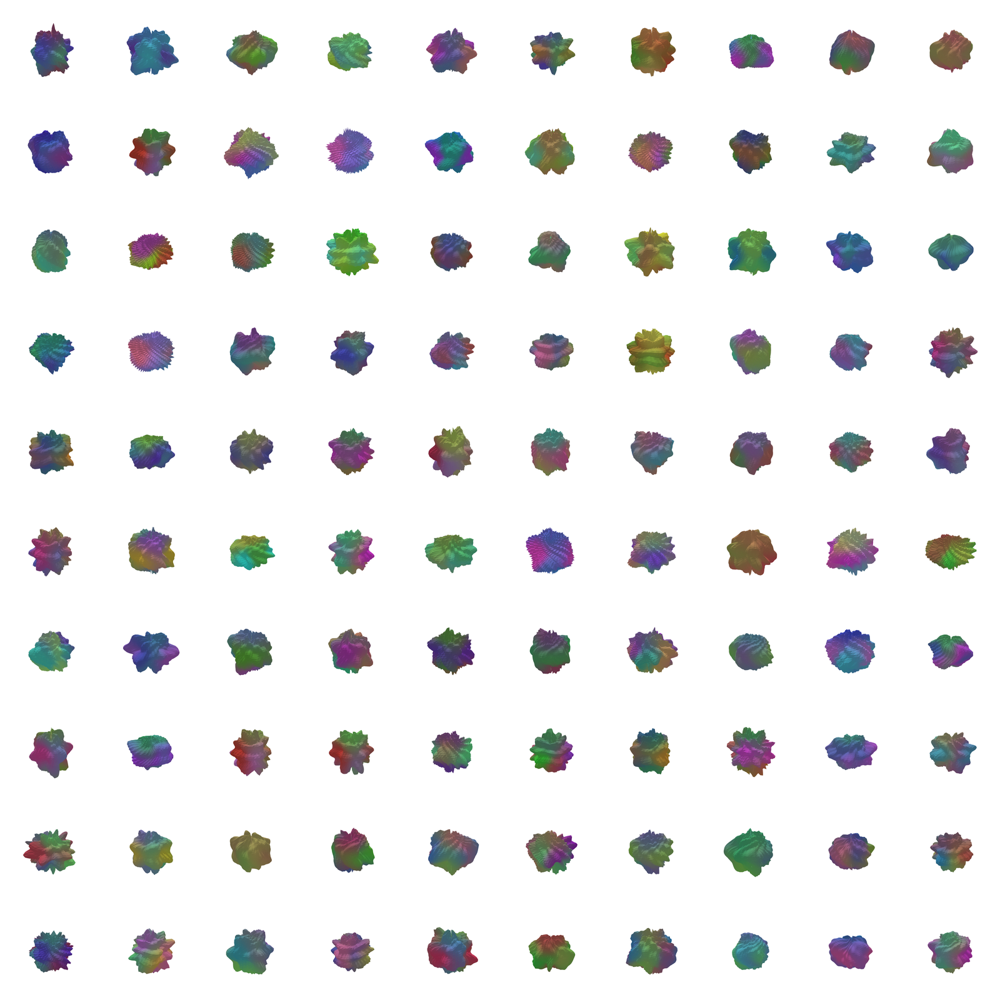

construction_40s.mp4 · 40 seconds · 800 frames · 20 fps


In [ ]:
#animate construction and color assignment, then rotate and zoom out to 100 samples

def ease(value):
    value = np.clip(value, 0, 1)
    return value * value * (3 - 2 * value)


def construction_state(seconds):
    if seconds < 2:
        return "Genotype input", 0, 0, 0, 38
    if seconds < 4:
        return "Latent encoding", 0, 0, 0, 38
    if seconds < 6:
        return "Base sphere", 0, 0, 0, 38
    if seconds < 11:
        return "Broad waves", 4 * (seconds - 6) / 5, 0, 0, 38
    if seconds < 13:
        return "Adding pleats", 4 + ease((seconds - 11) / 2), 0, 0, 38
    if seconds < 14:
        return "Fine ripples", 5 + ease(seconds - 13), 0, 0, 38
    if seconds < 16:
        return "Surface deformation", 6 + 3 * (seconds - 14) / 2, 0, 0, 38
    if seconds < 18:
        return "Palette assignment", 9, ease((seconds - 16) / 2), 0, 38
    if seconds < 21:
        return "Color blending", 9, 1, ease((seconds - 18) / 3), 38
    return "Surface rotation", 9, 1, 1, 38 + 85 * ease((seconds - 21) / 3)


def render_construction(counts, gallery_counts, filename, synthetic=False):
    if shutil.which("ffmpeg") is None:
        raise RuntimeError(
            'MP4 export requires FFmpeg. '
            "On Ubuntu run: sudo apt-get install ffmpeg"
        )
    counts = np.asarray(counts)
    gallery_counts = np.asarray(gallery_counts)
    if gallery_counts.shape != (100, 768):
        raise ValueError("The ending needs 100 genotype records with 768 sites each.")
    assert np.array_equal(counts, gallery_counts[44], equal_nan=True)
    vector = encode_counts(counts)
    vectors = encode_counts(gallery_counts)
    theta, phi = grid(72, 38)
    faces = triangles(*theta.shape)
    stages = [surface(vector, theta, phi, stage=s, time=phase) for s in range(10)]
    gallery_xyz = [surface(v, theta, phi, time=phase) for v in vectors]
    limit = max(np.max(np.abs(xyz)) for xyz in stages + gallery_xyz) * 1.08
    _, anchors, _, weights, rgb = color_parts(vector, theta, phi)
    face_rgb = rgb.reshape(-1, 3)[faces].mean(axis=1)

    fig = plt.figure(figsize=(video_size / 100, video_size / 100), dpi=100, facecolor="white")
    ax = fig.add_axes([0.03, 0.02, 0.94, 0.90], projection="3d")
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), zlim=(-limit, limit))
    ax.set_box_aspect((1, 1, 1), zoom=1.22)
    ax.set_axis_off()
    ax.view_init(24, 38)
    artist = Poly3DCollection(stages[0].reshape(-1, 3)[faces], edgecolors="none", linewidths=0)
    ax.add_collection3d(artist)
    label = fig.text(0.04, 0.96, "", va="top", fontsize=14, color="0.15")
    input_ax = fig.add_axes([0.12, 0.22, 0.76, 0.57])
    input_ax.imshow(
        counts.reshape(24, 32), cmap="gray_r", vmin=0, vmax=2, interpolation="nearest"
    )
    input_ax.set_axis_off()
    latent_ax = fig.add_axes([0.12, 0.25, 0.76, 0.5])
    latent_ax.bar(np.arange(12), vector, color="0.35")
    latent_ax.axhline(0, color="0.7", linewidth=0.8)
    latent_ax.set_axis_off()
    swatch_ax = fig.add_axes([0.65, 0.79, 0.27, 0.06])
    swatch_ax.imshow(anchors[None, :, :])
    swatch_ax.set_axis_off()
    field_ax = fig.add_axes([0.04, 0.09, 0.24, 0.16])
    field_ax.imshow(weights[..., 0], origin="lower", cmap="gray", vmin=0, vmax=1, aspect="auto")
    field_ax.set_axis_off()

    def draw_mesh(xyz, pigment, angle):
        mesh = xyz.reshape(-1, 3)[faces]
        artist.set_verts(mesh)
        artist.set_facecolor(face_shading(mesh)[:, None] * pigment)
        ax.view_init(24, angle)

    def pixels():
        fig.canvas.draw()
        return np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()


    for extra in [input_ax, latent_ax, swatch_ax, field_ax]:
        extra.set_visible(False)
    label.set_visible(False)
    tile = video_size
    atlas = RasterImage.new("RGB", (10 * tile, 10 * tile), "white")
    for i, xyz in enumerate(gallery_xyz):
        pigment = surface_colors(vectors[i], theta, phi).reshape(-1, 3)[faces].mean(axis=1)
        draw_mesh(xyz, pigment, 123)
        atlas.paste(RasterImage.fromarray(pixels()), ((i % 10) * tile, (i // 10) * tile))
    atlas.resize((1600, 1600), RasterImage.Resampling.LANCZOS).save(
        out / "images" / (pathlib.Path(filename).stem + "_grid.png")
    )
    label.set_visible(True)

    path = out / "animations" / filename
    temporary = path.with_suffix(".tmp.mp4")
    command = [
        "ffmpeg",
        "-y",
        "-loglevel",
        "error",
        "-f",
        "rawvideo",
        "-vcodec",
        "rawvideo",
        "-s",
        f"{video_size}x{video_size}",
        "-pix_fmt",
        "rgb24",
        "-r",
        str(video_fps),
        "-i",
        "-",
        "-an",
        "-c:v",
        "libx264",
        "-preset",
        "fast",
        "-crf",
        "18",
        "-pix_fmt",
        "yuv420p",
        "-movflags",
        "+faststart",
        str(temporary),
    ]
    from PIL import ImageDraw, ImageFont
    from matplotlib.font_manager import findfont

    font = ImageFont.truetype(findfont("DejaVu Sans"), round(video_size * 0.026))
    frames = 40 * video_fps
    with subprocess.Popen(command, stdin=subprocess.PIPE) as writer:
        try:
            for frame in range(frames):
                seconds = frame / video_fps
                if seconds < 24:
                    title, position, color_amount, mix_amount, angle = construction_state(
                        seconds
                    )
                    if synthetic and seconds < 2:
                        title = "Random genotype"
                    label.set_text(title)
                    input_ax.set_visible(seconds < 2)
                    latent_ax.set_visible(2 <= seconds < 4)
                    ax.set_visible(seconds >= 4)
                    swatch_ax.set_visible(16 <= seconds < 21)
                    field_ax.set_visible(18 <= seconds < 21)
                    lower = min(int(position), 8)
                    fraction = position - lower
                    if 6 <= seconds < 11 or 14 <= seconds < 16:
                        fraction = ease(fraction)
                    xyz = (1 - fraction) * stages[lower] + fraction * stages[lower + 1]
                    pigment = (1 - mix_amount) * anchors[0] + mix_amount * face_rgb
                    pigment = (1 - color_amount) * np.array(
                        [0.70, 0.72, 0.74]
                    ) + color_amount * pigment
                    draw_mesh(xyz, pigment, angle)
                    frame_pixels = pixels()
                else:
                    progress = ease((seconds - 25) / 10)
                    width = tile * 10**progress
                    center = tile * (4.5 + 0.5 * progress)
                    box = (
                        center - width / 2,
                        center - width / 2,
                        center + width / 2,
                        center + width / 2,
                    )
                    side = int(round(video_size * (1 - 0.10 * progress)))
                    crop = atlas.resize((side, side), RasterImage.Resampling.BICUBIC, box=box)
                    ending = RasterImage.new("RGB", (video_size, video_size), "white")
                    ending.paste(crop, ((video_size - side) // 2, video_size - side))
                    draw = ImageDraw.Draw(ending)
                    title = "Random genotypes" if synthetic else "Genotype variation"
                    draw.text(
                        (0.04 * video_size, 0.035 * video_size),
                        title,
                        font=font,
                        fill=(38, 38, 38),
                    )
                    frame_pixels = np.asarray(ending)
                if frame == 23 * video_fps and not synthetic:
                    RasterImage.fromarray(frame_pixels).save(
                        out / "images" / 'video_frame.png'
                    )
                writer.stdin.write(frame_pixels.tobytes())
                if frame % (10 * video_fps) == 0:
                    print(f"{filename}: {frame}/{frames} frames", flush=True)
        finally:
            writer.stdin.close()
            plt.close(fig)
        if writer.wait() != 0:
            raise RuntimeError("FFmpeg did not complete the video.")
    temporary.replace(path)
    save_npz(
        out / "data" / (path.stem + "_inputs.npz"),
        counts=counts,
        gallery_counts=gallery_counts,
        vector=vector,
        gallery_vectors=vectors,
    )
    experiment_results[path.stem] = {
        "seconds": 40,
        "frames": frames,
        "fps": video_fps,
        "rotation_degrees": 85,
        "synthetic_genotypes": synthetic,
        "gallery_records": 100,
        "anchor_index": 44,
        "fixed_latent_during_construction": True,
    }
    display(Video(str(path), embed=True, width=600))
    return path


if render_videos:
    other_indices = np.random.default_rng(2026).choice(
        np.delete(np.arange(len(Graw)), sample_index), size=99, replace=False
    )
    gallery_indices = np.insert(other_indices, 44, sample_index)
    real_video = render_construction(
        Graw[sample_index], Graw[gallery_indices], 'construction_40s.mp4'
    )
    experiment_results['construction_40s']["sample_ids"] = sample_ids[
        gallery_indices
    ].tolist()


## Random-input video

This version uses independent random counts for all 100 records. Change `random_video_seed` to generate a different set. The model and preprocessing stay fixed.

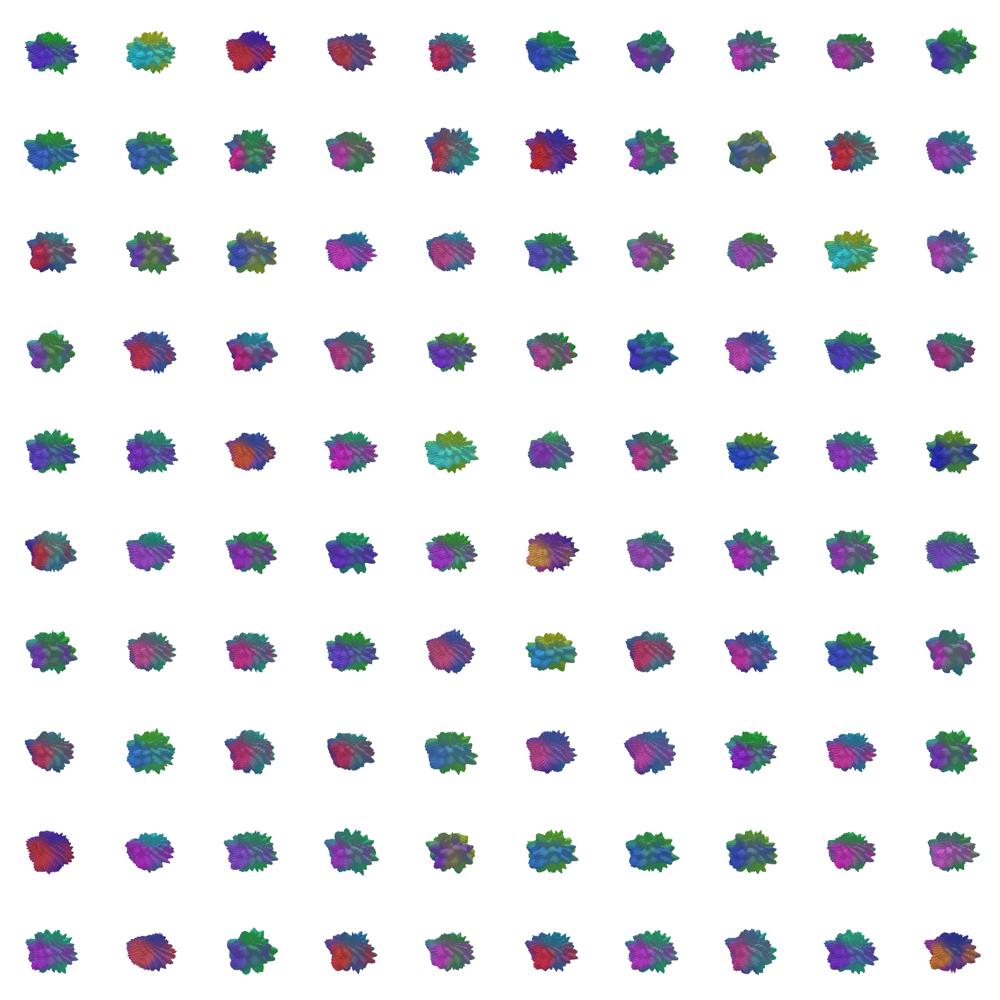

random_construction_40s.mp4 · 40 seconds · 800 frames · 20 fps


In [ ]:
#make the same construction video from random genotype inputs

random_video_seed = 2026
random_generator = np.random.default_rng(random_video_seed)
random_gallery = random_generator.integers(0, 3, size=(100, 768)).astype(np.float32)
random_gallery[[0, 44]] = random_gallery[[44, 0]]
if render_videos:
    random_video = render_construction(
        random_gallery[44], random_gallery, "random_construction_40s.mp4", synthetic=True
    )
    experiment_results["random_construction_40s"]["seed"] = random_video_seed


## Mesh exports

I export the original surfaces as OBJ files with vertex colors. The repaired versions are saved separately as OBJ and STL files using a 180 × 100 grid plus caps. Each repaired mesh is scaled uniformly to a longest dimension of 135 mm.

I also calculate surfaces for all 2,504 records and save their dimensions and geometry hashes. Only the three selected meshes are exported as individual files.

In [ ]:
#export the selected meshes at 135 mm and calculate the full series

def write_obj(path, vertices, faces, colors=None):
    with pathlib.Path(path).open("w") as handle:
        for i, vertex in enumerate(vertices):
            values = vertex if colors is None else np.r_[vertex, colors[i]]
            handle.write("v " + " ".join(f"{value:.8f}" for value in values) + "\n")
        for face in faces + 1:
            handle.write("f " + " ".join(map(str, face)) + "\n")


def write_stl(path, vertices, faces):
    mesh = vertices[faces]
    normals = np.cross(mesh[:, 1] - mesh[:, 0], mesh[:, 2] - mesh[:, 0])
    normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-15)
    with pathlib.Path(path).open("wb") as handle:
        handle.write(b"Geometry of Inheritance | coordinates in millimeters".ljust(80, b" "))
        handle.write(struct.pack("<I", len(faces)))
        for normal, triangle in zip(normals, mesh):
            handle.write(struct.pack("<12fH", *normal, *triangle.ravel(), 0))


export_reports = []
export_theta, export_phi = grid(180, 100)
for index in hero_indices:
    vector = Z[index]
    xyz = surface(vector, export_theta, export_phi, time=phase)
    vertices = xyz.reshape(-1, 3)
    colors = surface_colors(vector, export_theta, export_phi).reshape(-1, 3)
    faces = triangles(*export_theta.shape)
    name = str(sample_ids[index])
    write_obj(out / "meshes" / f"{name}_original.obj", vertices, faces, colors)
    closed_vertices, closed_faces, _, _ = close_mesh(vector, 180, 100)
    scale = 135 / np.ptp(closed_vertices, axis=0).max()
    closed_vertices = (
        closed_vertices - (closed_vertices.min(axis=0) + closed_vertices.max(axis=0)) / 2
    ) * scale
    dimensions = np.ptp(closed_vertices, axis=0)
    assert np.isclose(dimensions.max(), 135)
    write_obj(out / "meshes" / f"{name}_repair_135mm.obj", closed_vertices, closed_faces)
    write_stl(out / "meshes" / f"{name}_repair_135mm.stl", closed_vertices, closed_faces)
    report = mesh_report(closed_vertices, closed_faces)
    report.update(
        sample=name,
        dimensions_mm=dimensions.tolist(),
        scale_mm_per_unit=float(scale),
        intersection_status="Inspect this export separately in Blender before fabrication.",
    )
    export_reports.append(report)
experiment_results["exports"] = export_reports
print(json.dumps(export_reports, indent=2))


catalog_rows = [
    "sample_id,x_extent,y_extent,z_extent,min_red,max_red,min_green,max_green,min_blue,max_blue"
]
shape_hashes = []
for index, vector in enumerate(Z):
    xyz = surface(vector, T, P, time=phase)
    rgb = surface_colors(vector, T, P)
    assert np.isfinite(xyz).all() and np.isfinite(rgb).all()
    extent = np.ptp(xyz.reshape(-1, 3), axis=0)
    color_bounds = np.stack([rgb.min(axis=(0, 1)), rgb.max(axis=(0, 1))], axis=1).ravel()
    values = np.r_[extent, color_bounds]
    catalog_rows.append(str(sample_ids[index]) + "," + ",".join(f"{x:.8f}" for x in values))
    shape_hashes.append(hashlib.sha256(xyz.tobytes()).hexdigest())
(out / "data" / "series_catalog.csv").write_text("\n".join(catalog_rows) + "\n")
experiment_results["series"] = {
    "generated_surfaces": len(Z),
    "unique_geometry_hashes": len(set(shape_hashes)),
    "sampling": [120, 62],
    "geometry_sha256": shape_hashes,
}
print("Evaluated all", len(Z), "genotype-derived surfaces.")


[
  {
    "vertices": 18002,
    "triangles": 36000,
    "boundary_edges": 0,
    "nonmanifold_edges": 0,
    "euler_characteristic": 2,
    "minimum_triangle_area": 0.06229098274038542,
    "sample": "HG00096",
    "dimensions_mm": [
      118.60332683984402,
      110.74541373690637,
      135.0
    ],
    "scale_mm_per_unit": 38.92711840980651,
    "intersection_status": "Inspect this export separately in Blender before fabrication."
  },
  {
    "vertices": 18002,
    "triangles": 36000,
    "boundary_edges": 0,
    "nonmanifold_edges": 0,
    "euler_characteristic": 2,
    "minimum_triangle_area": 0.04557955277388311,
    "sample": "HG01498",
    "dimensions_mm": [
      135.0,
      130.8688357979707,
      113.55716059275309
    ],
    "scale_mm_per_unit": 39.22910686049827,
    "intersection_status": "Inspect this export separately in Blender before fabrication."
  },
  {
    "vertices": 18002,
    "triangles": 36000,
    "boundary_edges": 0,
    "nonmanifold_edges": 0,
    "eu

## Save outputs

Save the measurements as JSON and collect the generated files in one ZIP.

In [ ]:
#save the experiment results and zip the output folder

experiment_results["run"] = {
    "seed": seed,
    "training_steps": training_steps,
    "sample_index": sample_index,
    "phase": phase,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "data_sha256": hashlib.sha256(data_bytes).hexdigest(),
    "fit_scope": "All 2504 samples. Reported MSE is measured on the fitting data.",
}
(out / "experiment_results.json").write_text(json.dumps(experiment_results, indent=2))
archive = pathlib.Path(shutil.make_archive(str(out), "zip", out))
print("Saved", len(saved_plots), "figures and the experiment results.")
display(FileLink(str(archive)))


## References

- [1000 Genomes Phase 3](https://www.internationalgenome.org/data-portal/data-collection/phase3) · genotype data
- [Vincent et al., Stacked Denoising Autoencoders](https://jmlr.org/papers/v11/vincent10a.html) · denoising objective
- [Kingma and Ba, Adam](https://arxiv.org/abs/1412.6980) · optimizer
- [MIT OCW Fourier series notes](https://ocw.mit.edu/courses/es-1803-differential-equations-spring-2024/mites_1803_s24_topic21.pdf) · wave superposition
- [Strang, Calculus §15.4](https://ocw.mit.edu/ans7870/textbooks/Strang/Edited/Calculus/15.4-15.6.pdf) · parametric surfaces
- [MIT OCW spherical coordinates](https://ocw.mit.edu/courses/18-02-multivariable-calculus-fall-2007/c081c812df4a020e26de273c7cea957c_lec_week11.pdf) · coordinate conversion
- [TensorFlow softsign definition](https://www.tensorflow.org/api_docs/python/tf/keras/activations/softsign) · bounded coefficients
- [SciPy DCT tutorial](https://docs.scipy.org/doc/scipy/tutorial/fft.html#discrete-cosine-transforms) · cosine-transform normalization

The network, optimizer, and color calculations use NumPy. TensorFlow and SciPy are references only.

ChatGPT assisted with implementation, revisions, diagnostics, and packaging. The comparisons were reconstructed for the portfolio using the project equations and data.